# v2 checks (2026-11-19)

Checks on the v2-sweep (`-rand16`) models. Data: v2 (`_p5_n10000` × `_biasnoisenestv2_p9_n320000` × `_noisefly`), noise in θ. Continues from `2026-11-16_planning_for_v2.ipynb`.

**How to run:** run the two **shared setup** cells first. Then any part runs on its own, starting with that part's setup cell (if it has one). Within B, each subsection has its own setup cell, and B4 reuses the B3 setup.

- **A. Hyperparameter sweeps and ensembles** (sweeps at kp0.37 / kpgm0.24 / kb0.24)
  - A1. Sweep validation losses
  - A2. Ensembling: top-3 settings vs 3 seeds
- **B. Scale cuts**
  - B1. k_max grid (top model): FoB over (k_max^{P_gm}, k_max^B); Fig 9 with the top model
  - B2. Moving to k_max^{P_gm} = 0.37: hyperparameter transfer, kpgm slice with the top-3 ensemble (old hyperparameters)
  - B3. k_max^B slice with top-3 ensembles (new fiducial hyperparameters)
  - B4. Is the SHAMe FoB test strong enough? SHAMe vs phase-matched shifts along the kb slice
- **C. Prior leakage:** posterior samples outside the physical prior box
- **D. Paper Fig 7: SHAMe vs phase-matched across n̄**
  - D1. Top model only
  - D2. All cosmological and bias parameters

*Renumbered 2026-11-23.* Old § → new: 1→A1, 2→A2, 3→B1, 4→C, 5→D1, 6→B2, 7→B3, 8→D2, 9→B4. Scripts and memory notes from before that date use the old numbers.

## Shared setup

Run both cells first: paths and imports, then helpers shared across parts (sweep tables, SHAMe/FoB constants, mixture helpers, the failed-member rule).

In [1]:
import os
import sys
import re
import glob
import ast
from pathlib import Path

os.environ["MUCHISIMOCKS_DATA"] = "/scratch/kstoreyf/muchisimocks/data_v2"
os.environ["MUCHISIMOCKS_RESULTS"] = "/scratch/kstoreyf/muchisimocks/results_v2"

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import data_loader
import plotter
import paths

%load_ext autoreload
%autoreload 2

DIR_SBI = Path(paths.DIR_RESULTS) / "results_sbi"
FIG_DIR = REPO_ROOT / "figures" / "2026-11-19_v2_checks"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("results:", paths.DIR_RESULTS)

results: /scratch/kstoreyf/muchisimocks/results_v2


In [ ]:
# Shared helpers, used across parts: training/sweep logs, sweep tables, SHAMe / FoB constants, mixture helpers,
# and the failed-member rule. Run this and the cell above, then any part (A–D) on its own.
import itertools
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
from scipy.stats import chi2
import utils_inference
import plotter_figs

LOG_DIR_V2 = "/scratch/kstoreyf/muchisimocks/logs_v2"
HP_KEYS = ["hidden_features", "num_transforms", "learning_rate", "training_batch_size"]

# --- sweep tables: best validation loss per trial, parsed from the sweep logs (inference.p files are ~70 MB each).
# Each array task trains one trial; its log names the sweep's train config, the W&B run id and the chunked-training
# lines "epoch N: val loss X (best Y, ...)". Requeued tasks append to the same log, so the last "best" is the trial's
# best. Logs are matched to a sweep by their config (job names are not unique: a sweep at the current fiducial cuts
# has the bare name, e.g. sweep_v2_pk_pgm_bispec, whatever the fiducial was). Trials retired from the sweep
# (code_auxiliary/retire_sweep_trial.py, <sweep dir>/retired_trials.csv) are left out. Extension sweeps
# (<sweep yaml>_ext<n>.yaml, jobs/job_sweep_ext_v2.s; extra trials in the same dir) count as the same sweep.
def _sweep_log_index():
    rows = []
    for f in sorted(glob.glob(f"{LOG_DIR_V2}/sweep_v2_*_[0-9]*_[0-9]*.out")):
        t = open(f, errors="ignore").read().replace("\r", "\n")
        cfg = re.findall(r"^config_train_file: \S*/config_muchisimocks_(\S+)\.yaml", t, re.M)
        rid = re.findall(r"run-\d{8}_\d{6}-([a-z0-9]{8})", t)
        best = re.findall(r"epoch (\d+): val loss \S+ \(best (\S+),", t)
        if not (cfg and rid and best):
            continue
        hp = re.findall(r"^wandb\.config: (\{.*\})$", t, re.M)
        hp = ast.literal_eval(hp[-1]) if hp else {}
        ext = re.search(r"_ext(\d+)$", cfg[-1])
        rows.append({"sweep": "sbi_muchisimocks_" + re.sub(r"_ext\d+$", "", cfg[-1]), "ext": int(ext.group(1)) if ext else 0,
                     "run": rid[-1], "best_val_loss": float(best[-1][1]),
                     "n_epochs": int(best[-1][0]), **{k: hp.get(k) for k in HP_KEYS}})
    return pd.DataFrame(rows)

SWEEP_LOGS = _sweep_log_index()

def sweep_trials(prefix):
    """Trials of the -rand16 sweep whose results dir starts with prefix, sorted by best val loss."""
    dir_sweep = glob.glob(str(DIR_SBI / f"{prefix}_p5_n10000_*_sweep-rand16"))
    assert len(dir_sweep) == 1, dir_sweep
    dir_sweep = Path(dir_sweep[0])
    d = SWEEP_LOGS[SWEEP_LOGS["sweep"] == dir_sweep.name].drop(columns="sweep")
    fn_ret = dir_sweep / "retired_trials.csv"
    if fn_ret.is_file():
        d = d[~d["run"].isin(pd.read_csv(fn_ret)["run_id"])]
    d = d.assign(done=[(dir_sweep / r / "posterior.p").is_file() for r in d["run"]])
    return d.drop_duplicates("run", keep="last").sort_values("best_val_loss").reset_index(drop=True)

def seed_trials(job):
    """Best validation loss of the retrained seeds (>= 1); the newest log per seed wins (reruns append/new jobs)."""
    rows = {}
    for f in sorted(glob.glob(f"{LOG_DIR_V2}/{job}-[0-9]*_[0-9]*.out"), key=os.path.getmtime):
        t = open(f, errors="ignore").read().replace("\r", "\n")
        seed = re.findall(r"^train: \S*_best-rand16_seed(\d+)\.yaml", t, re.M)
        best = re.findall(r"epoch (\d+): val loss \S+ \(best (\S+),", t)
        if seed and best:
            rows[int(seed[-1])] = {"seed": int(seed[-1]), "best_val_loss": float(best[-1][1]),
                                   "n_epochs": int(best[-1][0]), "done": "Saved model to" in t}
    return pd.DataFrame(rows.values(), columns=["seed", "best_val_loss", "n_epochs", "done"]).sort_values("seed")

def train_log_table(log_glob):
    rows = {}
    for f in sorted(glob.glob(f"{LOG_DIR_V2}/{log_glob}"), key=os.path.getmtime):   # newest last -> wins
        t = open(f, errors="ignore").read().replace("\r", "\n")
        cfg = re.findall(r"^train: \S*config_muchisimocks_(\S+)\.yaml", t, re.M)
        best = re.findall(r"epoch (\d+): val loss \S+ \(best (\S+),", t)
        if cfg and best:
            rows[cfg[-1]] = {"best_val_loss": float(best[-1][1]), "n_epochs": int(best[-1][0]),
                             "done": "Saved model to" in t}
    return rows

# the 4 sweeps at the original cuts (kp0.37 / kpgm0.24 / kb0.24); extra seeds of each sweep's best run (best_runs.txt
# line 0; seed 0 is the rank-1 trial itself), from code_auxiliary/make_best_seeds_list_v2.py
SWEEPS = {   # label: (stats tag, sweep results dir prefix)
    "P": ("pk", "sbi_muchisimocks_pk_kp0.37"),
    "P + P$_{\\rm gm}$": ("pk_pgm", "sbi_muchisimocks_pk_pgm_kp0.37_kpgm0.24"),
    "P + B": ("pk_bispec", "sbi_muchisimocks_pk_bispec_kp0.37_kb0.24"),
    "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", "sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24"),
}
SEED_JOBS = {lab: f"train_v2_bestseeds_{st}" for lab, (st, _) in SWEEPS.items()}
df_sweeps = {lab: sweep_trials(prefix) for lab, (_, prefix) in SWEEPS.items()}
df_seeds = {lab: seed_trials(SEED_JOBS[lab]) for lab in SWEEPS}

# --- SHAMe mocks and the figure of bias
NBARS = ["0.00011", "0.00022", "0.00054"]
NBAR_LABS = {"0.00011": r"$\bar{n}=1.1\times10^{-4}$", "0.00022": r"$\bar{n}=2.2\times10^{-4}$",
             "0.00054": r"$\bar{n}=5.4\times10^{-4}$"}
MOCK_LABS = {"shame": "SHAMe", "matched": "phase-matched mean"}
FOB_PARAMS = ["omega_cold", "sigma8_cold", "b1"]
REF3 = float(np.sqrt(chi2.ppf(0.682689492137, 3)))
TRUTH_K = {nb: data_loader.load_params_ood("shame", f"_nbar{nb}") for nb in NBARS}
TRUTH_K = {nb: np.array([float(t[p]) for p in FOB_PARAMS]) for nb, t in TRUTH_K.items()}

def fob_and_fom6(samps, names, nbar):
    # FoB(Ω_c, σ8, b1)/1σ and FoM = 1/sqrt(det C) in (Ω_c, σ8, b1), from (reparameterized) samples
    mu, cov, nm = utils_inference.physical_moments_from_samples(samps, names)
    idx = [list(nm).index(p) for p in FOB_PARAMS]
    c3, diff = cov[np.ix_(idx, idx)], mu[idx] - TRUTH_K[nbar]
    return float(np.sqrt(diff @ np.linalg.solve(c3, diff))) / REF3, 1 / np.sqrt(np.linalg.det(c3))

def mix6(rs, seed=0):
    rng = np.random.default_rng(seed)
    n = min(s.shape[0] for s, _ in rs) // len(rs)
    assert all(nm == rs[0][1] for _, nm in rs), "members disagree on param_names"
    return np.concatenate([s[rng.choice(s.shape[0], n, replace=False)] for s, _ in rs]), rs[0][1]

# --- top-3 members along the k_max slices and the failed-member rule (agreed 2026-11-22): a member whose best val NLL
# is more than RETRAIN_THR6 above the best member at its cut is a failed training -> retrained with the next seed.
SETTINGS6 = {"": "setting 1", "_nbest1": "setting 2", "_nbest2": "setting 3"}   # best_runs.txt lines 0, 1, 2
COLORS6 = {"setting 1": "#2a78d6", "setting 2": "#eb6834", "setting 3": "#1baf7a"}
MARKERS6 = {"setting 1": "o", "setting 2": "s", "setting 3": "^"}
RETRAIN_THR6 = 0.4
K_SLICE6 = list(data_loader.K_CUTS)
# seed-to-seed scatter of the top P+P_gm+B setting at the original fiducial cut: reference scale for "network noise"
_fid_sweep = df_sweeps["P + P$_{\\rm gm}$ + B"]
SEED_SCATTER6 = np.abs(df_seeds["P + P$_{\\rm gm}$ + B"]["best_val_loss"].values - _fid_sweep["best_val_loss"][0]).max()
print(f"seed scatter of the top setting at the fiducial cut (max |Δ| vs seed 0): {SEED_SCATTER6:.3f} nats")

## A. Hyperparameter sweeps and ensembles

Needs the shared setup only. A2 has its own setup cell.

### A1. v2 hyperparameter sweeps: sorted best validation loss

One panel per statistics combination (`-rand16` sweeps at kp0.37 / kpgm0.24 / kb0.24, noise in θ). Each point is one trial's best validation loss (NLL, lower is better), sorted, so a clear gap after the first few trials shows whether there is a distinct top group. Open points are trials still training, plotted at their current best. Orange diamonds at rank 1 are the rank-1 hyperparameters retrained with other seeds (seeds 1 and 2; the rank-1 point is seed 0), which show how much of the spread between trials is seed noise. The dotted line marks the top 3 (`choose_best_run.py --n-passing 3` keeps the top 3 trials that also pass the coverage and SHAMe checks). Losses can only be compared within a panel, since each combination has a different data vector.

In [ ]:
# best validation loss per v2 sweep trial (df_sweeps, df_seeds from the shared helpers)
fig, axes = plt.subplots(1, len(df_sweeps), figsize=(4 * len(df_sweeps), 3.6))
for ax, (lab, d) in zip(axes, df_sweeps.items()):
    rank = np.arange(1, len(d) + 1)
    ax.plot(rank, d["best_val_loss"], "-", color="0.75", lw=1, zorder=1)
    ax.scatter(rank[d["done"]], d["best_val_loss"][d["done"]], color="#6BB756", s=30, zorder=2, label="finished")
    if (~d["done"]).any():
        ax.scatter(rank[~d["done"]], d["best_val_loss"][~d["done"]], facecolor="none", edgecolor="#1F2F6B",
                   s=30, zorder=2, label="still training")
    ds = df_seeds[lab]   # extra seeds of the rank-1 hyperparameters, drawn at rank 1
    if len(ds):
        done = ds["done"].values
        ax.scatter(np.ones(done.sum()), ds["best_val_loss"][done], marker="D", color="#E08A2E", s=28, zorder=3,
                   label="rank-1 hyperparameters, other seeds")
        if (~done).any():
            ax.scatter(np.ones((~done).sum()), ds["best_val_loss"][~done], marker="D", facecolor="none",
                       edgecolor="#E08A2E", s=28, zorder=3, label="other seed, still training")
    if (~d["done"]).any() or len(ds):
        ax.legend(fontsize=7)
    ax.axvline(3.5, color="0.5", ls=":", lw=1)   # choose_best_run keeps the top 3 that pass the checks
    ax.set_title(f"{lab} ({len(d)} trials)")
    ax.set_xlabel("rank")
    ax.set_xticks(rank[::3])
axes[0].set_ylabel("best validation loss (NLL)")
fig.suptitle("v2 sweeps (-rand16): best validation loss per trial, sorted", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "sweep_v2_best_val_loss_sorted.pdf", bbox_inches="tight")
plt.show()

for lab, d in df_sweeps.items():
    print(lab, "| gap rank1→2, 2→3, 3→4:", np.round(np.diff(d["best_val_loss"].values[:4]), 3))
    print(d.head(6).round(4).to_string())
    if len(df_seeds[lab]):
        print("rank-1 hyperparameters, other seeds:\n" + df_seeds[lab].round(4).to_string(index=False))
    print()


In [ ]:
# A1b. Sweeps at the new fiducial k_max^{P_gm} = 0.37: the two P_gm combos (P and P+B are unchanged, see above).
# Val NLL is only comparable within one set of cuts: kpgm0.37 adds P_gm bins, so the data vector differs and the
# NLL sits lower than in the kpgm0.24 sweeps above. Rank order and gaps are what matter.
# Circles: the 16 original trials (open = still training); squares: extension trials (ext1, added 2026-11-23 to look
# for a better 3rd setting, sweep dir SWEEP_SIZE_NOTE.md); red ×: retired trial (retire_sweep_trial.py), drawn at the
# rank it had; orange diamonds: seed-1 retrains of the top 3 settings (the fresh ensemble members), at their rank.
SWEEPS_NEW = {"P + P$_{\\rm gm}$": "sbi_muchisimocks_pk_pgm_kp0.37_kpgm0.37",
              "P + P$_{\\rm gm}$ + B": "sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.37_kb0.24"}
TAIL_A1B = "_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16-topkpgm0.37"
df_sweeps_new = {lab: sweep_trials(p) for lab, p in SWEEPS_NEW.items()}
vl_seed1 = {}
for g in ("train_kbslice_top3_*.out", "train_ppb_nbest2_rand16-*.out", "train_kbslice_retrain_rand16-*.out",
          "train_pkpgm_fiducial_rand16-*.out"):
    vl_seed1.update(train_log_table(g))

def retired_trials(prefix):
    fn = glob.glob(str(DIR_SBI / f"{prefix}_p5_n10000_*_sweep-rand16" / "retired_trials.csv"))
    return pd.read_csv(fn[0]) if fn else pd.DataFrame(columns=["run_id", "best_validation_loss"])

fig, axes = plt.subplots(1, len(SWEEPS_NEW), figsize=(5.2 * len(SWEEPS_NEW), 3.8), squeeze=False)
for ax, (lab, prefix) in zip(axes[0], SWEEPS_NEW.items()):
    d = df_sweeps_new[lab]
    rank = np.arange(1, len(d) + 1)
    ax.plot(rank, d["best_val_loss"], "-", color="0.75", lw=1, zorder=1)
    for ext, marker, name in ((0, "o", "original trial"), (1, "s", "extension trial (ext1)")):
        sel = (d["ext"] == ext).values
        if not sel.any():
            continue
        dn = d["done"].values
        ax.scatter(rank[sel & dn], d["best_val_loss"][sel & dn], marker=marker, color="#6BB756", s=30, zorder=2, label=name)
        ax.scatter(rank[sel & ~dn], d["best_val_loss"][sel & ~dn], marker=marker, facecolor="none", edgecolor="#1F2F6B",
                   s=30, zorder=2, label=f"{name}, still training" if (sel & ~dn).any() else None)
    for r in retired_trials(prefix).itertuples():
        rk = 1 + (d["best_val_loss"] < r.best_validation_loss).sum()
        ax.scatter(rk, r.best_validation_loss, marker="x", color="#c0392b", s=50, lw=1.8, zorder=3,
                   label=f"retired ({r.run_id})")
    for i, member in enumerate(["", "_nbest1", "_nbest2"]):
        v = vl_seed1.get(prefix[len("sbi_muchisimocks_"):] + TAIL_A1B + member + "_seed1")
        if v is not None:
            ax.scatter(i + 1 + 0.25, v["best_val_loss"], marker="D", s=28, zorder=3,
                       color="#E08A2E" if v["done"] else "none", edgecolor="#E08A2E",
                       label="seed-1 retrain of settings 1–3" if i == 0 else None)
    ax.axvline(3.5, color="0.5", ls=":", lw=1)
    ax.set_title(f"{lab}, kpgm0.37 ({len(d)} trials)")
    ax.set_xlabel("rank"); ax.set_xticks(rank[::3])
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel("best validation loss (NLL)")
fig.suptitle("v2 sweeps at the new fiducial $k_{\\rm max}^{P_{\\rm gm}}=0.37$: best validation loss per trial, sorted", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "sweep_v2_kpgm037_best_val_loss_sorted.pdf", bbox_inches="tight")
plt.show()

for lab, d in df_sweeps_new.items():
    print(lab, "| gap rank1→2, 2→3, 3→4:", np.round(np.diff(d["best_val_loss"].values[:4]), 3))
    print(d.head(6).round(4).to_string())
    print()

### A2. Ensembling the v2 models: top-3 hyperparameter settings vs 3 seeds of the top setting

`-rand16` sweep models at the fiducial cuts (kp0.37 / kpgm0.24 / kb0.24, noise in θ), for every statistics combination. We compare two equal-weight posterior mixtures:
- **top-3 settings:** best_runs.txt lines 0–2 of the sweep, seed 0 each (`best-rand16`, `_nbest1`, `_nbest2`);
- **3 seeds:** the top setting retrained with seeds 0, 1 and 2 (`best-rand16`, `_seed1`, `_seed2`).

Both mixtures share the top-setting seed-0 network. Coverage uses the full `inner500` subset of the v2 coverage set (the 500 rows farthest from the prior edges in Ω_c, σ8 and b1). The top setting, seed 0 is run on all 1000 rows (for paper Figs 4/5), and we take its inner500 rows here. Tests come from `code_auxiliary/make_ensemble_tests_rand16.py`. A model whose test is still running is plotted from its partial samples (`_pred_inprogress.npy`, finished rows only), with n in the legend. This section runs on its own after the first setup cell.


In [3]:
# A2 setup: rand16 models, loaders and P-P helpers
import utils_inference
import plotter_figs

DIR_SBI = Path(paths.DIR_RESULTS) / "results_sbi"
R16_COMBOS = {   # label: (stats tag as in the sweep dir, masks)
    "P": ("pk", "_kp0.37"),
    "P + P$_{\\rm gm}$": ("pk_pgm", "_kp0.37_kpgm0.24"),
    "P + B": ("pk_bispec", "_kp0.37_kb0.24"),
    "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", "_kp0.37_kpgm0.24_kb0.24"),
}
R16_COLORS = dict(zip(R16_COMBOS, plotter_figs.COLORS_FID))   # paper color per combo (filled = 3 seeds)
COLOR_TOP3 = "#1F2F6B"                                          # navy (outlines) = top-3 settings
R16_MEMBERS = {"top-3 settings": ["", "_nbest1", "_nbest2"], "3 seeds": ["", "_seed1", "_seed2"]}
KEY3 = ["omega_cold", "sigma8_cold", "b1"]
KEY3_LABELS = {"omega_cold": r"$\Omega_{\rm c}$", "sigma8_cold": r"$\sigma_8$", "b1": r"$b_1$"}
TAG_COV16 = "_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly"
SUB16 = "inner500"

def r16_dir(stats, masks, member):
    return DIR_SBI / f"sbi_muchisimocks_{stats}{masks}_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16{member}"

def to_key3(s, names):
    # (..., n_params) reparameterized samples -> (..., 3) physical (Ω_c, σ8, b1)
    s, names = utils_inference.unreparameterize_theta(np.asarray(s, dtype=np.float64), list(names), strict=False)
    names = list(names)
    return s[..., [names.index(k) for k in KEY3]]

idxs16 = np.load(REPO_ROOT / "data" / "params" / f"idxs_obs_coveragev2_p5_n1000_{SUB16}.npy")
_cos16 = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_coveragev2_p5_n1000.txt", index_col=0)
_bia16 = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_biasnoisecoveragev2_p9_n1000.txt", index_col=0)
truth16 = np.stack([_cos16.loc[idxs16, "omega_cold"], _cos16.loc[idxs16, "sigma8_cold"], _bia16.loc[idxs16, "b1"]], axis=1)

def load_cov16(stats, masks, member):
    # (n_samples, 500, 3) physical; unfinished rows are NaN. Returns (samples, "done"/"inprogress") or (None, None).
    # The top setting, seed 0 (member "") runs the full 1000-row coverage set; its inner500 rows are taken from it.
    d = r16_dir(stats, masks, member)
    base = f"samples_test_muchisimocks_{stats}{masks}{TAG_COV16}" + ("" if member == "" else f"_{SUB16}")
    for suffix, kind in (("_pred.npy", "done"), ("_pred_inprogress.npy", "inprogress")):
        f = d / (base + suffix)
        if f.exists():
            s = np.load(f, mmap_mode="r")
            if member == "":
                assert s.shape[1] == len(_cos16), (f, s.shape)
                s = s[:, idxs16]
            s = to_key3(s, np.loadtxt(d / "param_names.txt", dtype=str))
            assert s.shape[1] == len(idxs16), (f, s.shape)
            return s, kind
    return None, None

def mix16(arrs, seed=0):
    # equal-weight mixture over the first axis (works for (n, n_obs, 3) and (n, 3))
    rng = np.random.default_rng(seed)
    n = min(a.shape[0] for a in arrs) // len(arrs)
    return np.concatenate([a[rng.choice(a.shape[0], n, replace=False)] for a in arrs], axis=0)

CRED16 = np.linspace(0, 1, 51)
def pp16(s):
    # P-P curves (3, n_levels) over rows finished in s, and the number of rows used
    ok = np.isfinite(s).all(axis=(0, 2))
    ranks = (s[:, ok, :] < truth16[ok][None]).mean(axis=0)
    a = 2 * np.abs(ranks - 0.5)
    return np.stack([(a[:, j][:, None] <= CRED16[None]).mean(axis=0) for j in range(3)]), ok.sum()

cov16 = {(lab, m): load_cov16(st, mk, m) for lab, (st, mk) in R16_COMBOS.items()
         for m in sorted(set(sum(R16_MEMBERS.values(), [])))}
for (lab, m), (s, kind) in cov16.items():
    n = None if s is None else int(np.isfinite(s).all(axis=(0, 2)).sum())
    print(f"{lab:24s} {('top' + m) if m else 'top seed0':12s} {kind or 'missing'} {'' if n is None else f'({n}/500 rows)'}")


2026-11-20 22:15:29.404879: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-20 22:15:29.451214: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-20 22:15:29.562618: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-20 22:15:29.562671: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-20 22:15:29.578857: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

2026-11-20 22:15:31.243514: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


P                        top seed0    done (500/500 rows)
P                        top_nbest1   done (500/500 rows)
P                        top_nbest2   done (500/500 rows)
P                        top_seed1    done (500/500 rows)
P                        top_seed2    done (500/500 rows)
P + P$_{\rm gm}$         top seed0    done (500/500 rows)
P + P$_{\rm gm}$         top_nbest1   done (500/500 rows)
P + P$_{\rm gm}$         top_nbest2   done (500/500 rows)
P + P$_{\rm gm}$         top_seed1    done (500/500 rows)
P + P$_{\rm gm}$         top_seed2    done (500/500 rows)
P + B                    top seed0    done (500/500 rows)
P + B                    top_nbest1   done (500/500 rows)
P + B                    top_nbest2   done (500/500 rows)
P + B                    top_seed1    done (500/500 rows)
P + B                    top_seed2    done (500/500 rows)


P + P$_{\rm gm}$ + B     top seed0    done (500/500 rows)
P + P$_{\rm gm}$ + B     top_nbest1   done (500/500 rows)
P + P$_{\rm gm}$ + B     top_nbest2   done (500/500 rows)
P + P$_{\rm gm}$ + B     top_seed1    done (500/500 rows)
P + P$_{\rm gm}$ + B     top_seed2    done (500/500 rows)


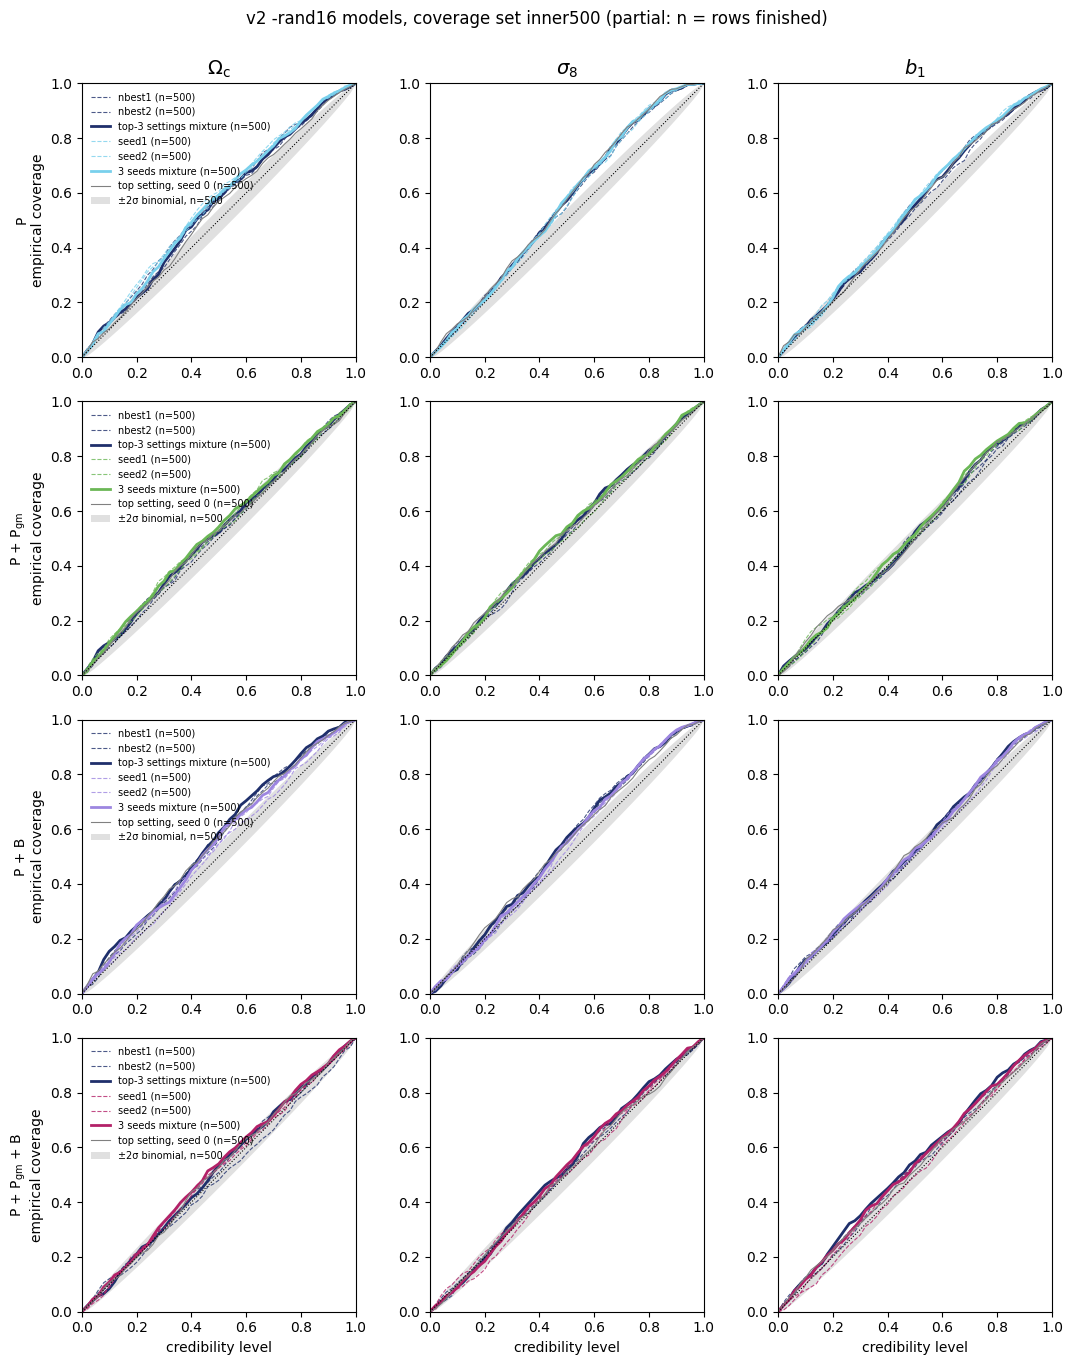

In [4]:
fig, axes = plt.subplots(len(R16_COMBOS), 3, figsize=(11, 3.4 * len(R16_COMBOS)), squeeze=False)
n_mix = {lab: [] for lab in R16_COMBOS}   # rows used per mixture
n_ind = {lab: [] for lab in R16_COMBOS}   # rows per individual network
for r, lab in enumerate(R16_COMBOS):
    for ens, members in R16_MEMBERS.items():
        color = COLOR_TOP3 if ens == "top-3 settings" else R16_COLORS[lab]
        arrs = [cov16[(lab, m)][0] for m in members]
        for m, a in zip(members, arrs):          # individual networks, thin
            if a is None or m == "":             # seed-0 top network is drawn once, in grey
                continue
            pp, n = pp16(a)
            n_ind[lab].append(n)
            for c in range(3):
                axes[r, c].plot(CRED16, pp[c], color=color, lw=0.8, ls="--", alpha=0.8,
                                label=f"{m.strip('_')} (n={n})" if c == 0 else None)
        if all(a is not None for a in arrs):
            # mixtures use only rows finished in all three members
            ok = np.all([np.isfinite(a).all(axis=(0, 2)) for a in arrs], axis=0)
            pp, n = pp16(mix16([np.where(ok[None, :, None], a, np.nan) for a in arrs]))
            n_mix[lab].append(n)
            for c in range(3):
                axes[r, c].plot(CRED16, pp[c], color=color, lw=2.0, label=f"{ens} mixture (n={n})" if c == 0 else None)
    a0 = cov16[(lab, "")][0]
    if a0 is not None:
        pp, n = pp16(a0)
        n_ind[lab].append(n)
        for c in range(3):
            axes[r, c].plot(CRED16, pp[c], color="0.5", lw=0.8, label=f"top setting, seed 0 (n={n})" if c == 0 else None)
    # ±2σ binomial band for the mixtures' row count (the smaller one); if no mixture yet, for the fewest rows plotted
    n_band = min(n_mix[lab]) if n_mix[lab] else min(n_ind[lab], default=0)
    band = 2 * np.sqrt(CRED16 * (1 - CRED16) / max(n_band, 1))
    for c, p in enumerate(KEY3):
        ax = axes[r, c]
        if n_band:
            ax.fill_between(CRED16, CRED16 - band, CRED16 + band, color="0.88", lw=0,
                            label=f"±2σ binomial, n={n_band}" if c == 0 else None)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        if r == 0:
            ax.set_title(KEY3_LABELS[p], fontsize=14)
        if r == len(R16_COMBOS) - 1:
            ax.set_xlabel("credibility level")
    axes[r, 0].set_ylabel(f"{lab}\nempirical coverage", fontsize=10)
    axes[r, 0].legend(fontsize=7, loc="upper left", frameon=False)
fig.suptitle(f"v2 -rand16 models, coverage set {SUB16} (partial: n = rows finished)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / f"coverage_pp_rand16_ensembles_{SUB16}.pdf", bbox_inches="tight")
plt.show()


In [5]:
# Per network and per mixture: mean (coverage − credibility) over levels (+ = conservative, − = overconfident),
# coverage of the central 68% / 95% intervals, median posterior σ
rows16 = []
def summarize16(combo, model, s):
    pp, n = pp16(s)
    row = {"combo": combo, "model": model, "n": n}
    for c, p in enumerate(KEY3):
        row[(p, "mean Δ")] = (pp[c] - CRED16).mean()
        row[(p, "cov68")] = np.interp(0.68, CRED16, pp[c])
        row[(p, "cov95")] = np.interp(0.95, CRED16, pp[c])
        row[(p, "med σ")] = np.nanmedian(s[:, :, c].std(axis=0))
    rows16.append(row)
for lab in R16_COMBOS:
    for m in ["", "_seed1", "_seed2", "_nbest1", "_nbest2"]:
        s = cov16[(lab, m)][0]
        if s is not None:
            summarize16(lab, m.strip("_") or "top, seed0", s)
    for ens, members in R16_MEMBERS.items():
        arrs = [cov16[(lab, m)][0] for m in members]
        if all(a is not None for a in arrs):
            ok = np.all([np.isfinite(a).all(axis=(0, 2)) for a in arrs], axis=0)
            summarize16(lab, f"mixture: {ens}", mix16([np.where(ok[None, :, None], a, np.nan) for a in arrs]))
if rows16:
    df_cov16 = pd.DataFrame(rows16).set_index(["combo", "model"])
    df_cov16.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in df_cov16.columns])
    print(f"±2σ binomial scatter at n=500: cov68 ≈ ±{2*np.sqrt(.68*.32/500):.3f}, cov95 ≈ ±{2*np.sqrt(.95*.05/500):.3f}")
    display(df_cov16.round(3))
else:
    print("no rand16 coverage samples yet")


±2σ binomial scatter at n=500: cov68 ≈ ±0.042, cov95 ≈ ±0.019


n omega_cold                \
                                                      mean Δ  cov68  cov95   
combo                model                                                   
P                    top, seed0               500      0.031  0.728  0.972   
                     seed1                    500      0.058  0.754  0.974   
                     seed2                    500      0.068  0.772  0.983   
                     nbest1                   500      0.041  0.746  0.974   
                     nbest2                   500      0.059  0.758  0.974   
                     mixture: top-3 settings  500      0.047  0.740  0.975   
                     mixture: 3 seeds         500      0.057  0.754  0.978   
P + P$_{\rm gm}$     top, seed0               500      0.016  0.688  0.944   
                     seed1                    500      0.015  0.694  0.949   
                     seed2                    500      0.029  0.722  0.965   
                     nbest1                   500      0.008  0.688  0.950   
                     nbest2                   500      0.018  0.690  0.962   
                     mixture: top-3 settings  500      0.021  0.698  0.961   
                     mixture: 3 seeds         500      0.030  0.706  0.957   
P + B                top, seed0               500      0.051  0.750  0.980   
                     seed1                    500      0.019  0.710  0.967   
                     seed2                    500      0.036  0.720  0.967   
                     nbest1                   500      0.049  0.766  0.978   
                     nbest2                   500      0.050  0.762  0.981   
                     mixture: top-3 settings  500      0.060  0.778  0.981   
                     mixture: 3 seeds         500      0.044  0.734  0.975   
P + P$_{\rm gm}$ + B top, seed0               500      0.011  0.692  0.954   
                     seed1                    500      0.008  0.684  0.950   
                     seed2                    500      0.012  0.696  0.948   
                     nbest1                   500     -0.015  0.646  0.939   
                     nbest2                   500      0.015  0.710  0.954   
                     mixture: top-3 settings  500      0.013  0.696  0.960   
                     mixture: 3 seeds         500      0.022  0.694  0.963   

                                                    sigma8_cold                \
                                              med σ      mean Δ  cov68  cov95   
combo                model                                                      
P                    top, seed0               0.029       0.062  0.790  0.996   
                     seed1                    0.030       0.061  0.796  0.995   
                     seed2                    0.031       0.046  0.770  0.995   
                     nbest1                   0.029       0.050  0.770  0.994   
                     nbest2                   0.030       0.057  0.784  0.994   
                     mixture: top-3 settings  0.030       0.057  0.782  0.996   
                     mixture: 3 seeds         0.030       0.057  0.792  0.996   
P + P$_{\rm gm}$     top, seed0               0.016       0.019  0.698  0.954   
                     seed1                    0.016       0.022  0.704  0.971   
                     seed2                    0.016       0.008  0.690  0.956   
                     nbest1                   0.016       0.013  0.704  0.956   
                     nbest2                   0.016       0.009  0.698  0.960   
                     mixture: top-3 settings  0.016       0.020  0.714  0.962   
                     mixture: 3 seeds         0.016       0.023  0.710  0.966   
P + B                top, seed0               0.026       0.038  0.734  0.981   
                     seed1                    0.024       0.030  0.742  0.980   
                     seed2                    0.025       0.026  0.732  0.979   
         

#### A2b. SHAMe posteriors: top-3 settings vs 3 seeds

SHAMe high-fidelity mock at $\bar{n}=2.2\times10^{-4}$, for Ω_c, σ8 and physical b1. Each figure shows one statistics combination. The 3-seed mixture is filled, in the paper color for that combination. The top-3-settings mixture is drawn as navy outlines, with thin navy lines marking its 1D 68% interval. Black dashed lines mark the SHAMe truth.


SHAMe truth: {'sigma8_cold': 0.816, 'omega_cold': 0.309, 'b1': 0.474}


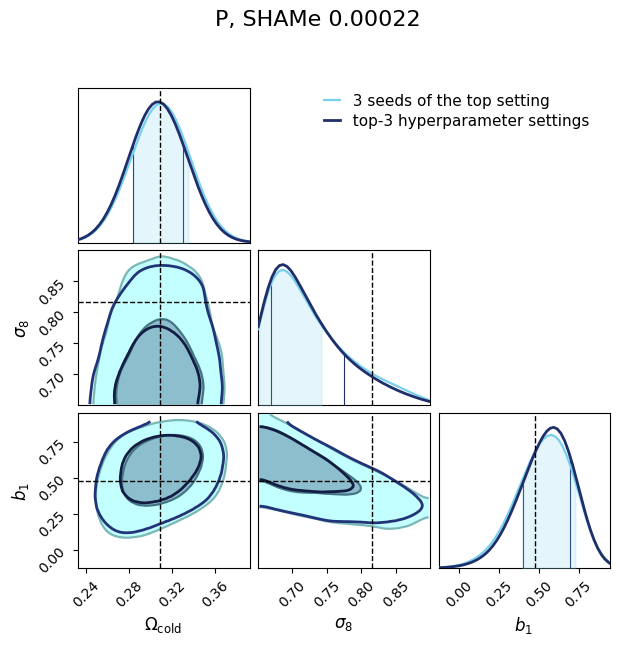

  3 seeds bias/σ: omega_cold=+0.01, sigma8_cold=-1.67, b1=+0.40 | σ: omega_cold=0.0230, sigma8_cold=0.0561, b1=0.1530
  top-3  bias/σ: omega_cold=-0.08, sigma8_cold=-1.83, b1=+0.50 | σ: omega_cold=0.0227, sigma8_cold=0.0533, b1=0.1466


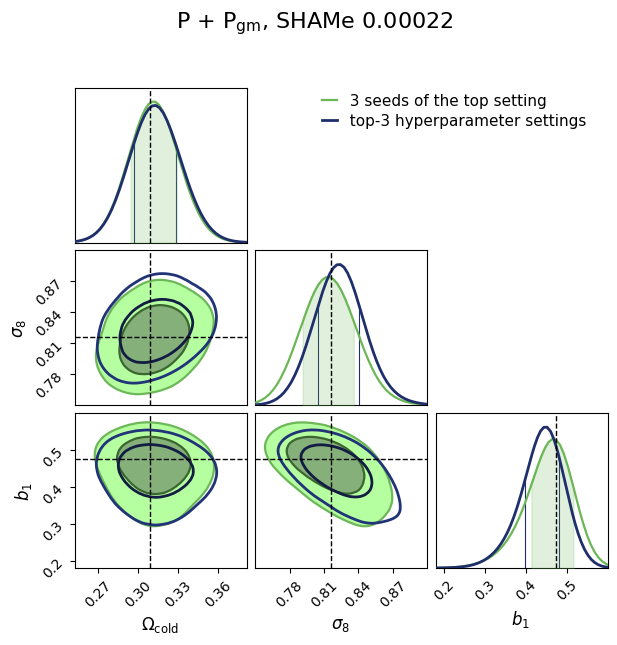

  3 seeds bias/σ: omega_cold=+0.21, sigma8_cold=-0.06, b1=-0.43 | σ: omega_cold=0.0156, sigma8_cold=0.0200, b1=0.0482
  top-3  bias/σ: omega_cold=+0.26, sigma8_cold=+0.40, b1=-0.80 | σ: omega_cold=0.0158, sigma8_cold=0.0188, b1=0.0442


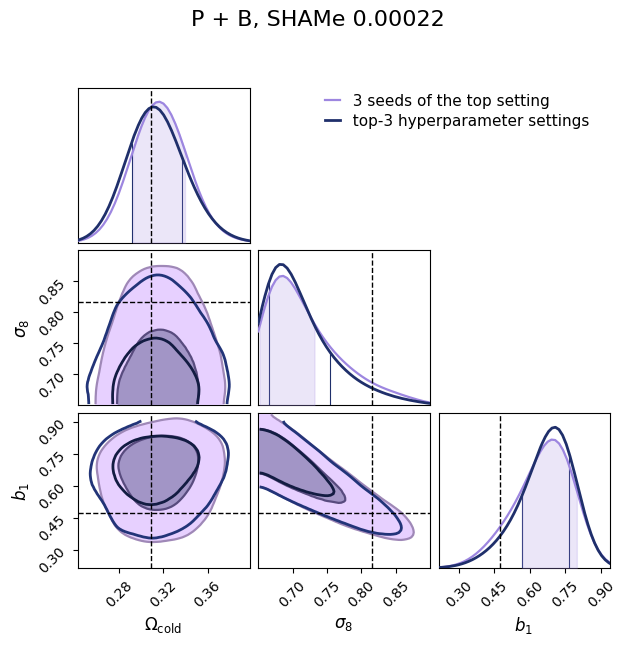

  3 seeds bias/σ: omega_cold=+0.37, sigma8_cold=-1.94, b1=+1.68 | σ: omega_cold=0.0215, sigma8_cold=0.0518, b1=0.1089
  top-3  bias/σ: omega_cold=+0.22, sigma8_cold=-2.26, b1=+1.89 | σ: omega_cold=0.0231, sigma8_cold=0.0474, b1=0.1031


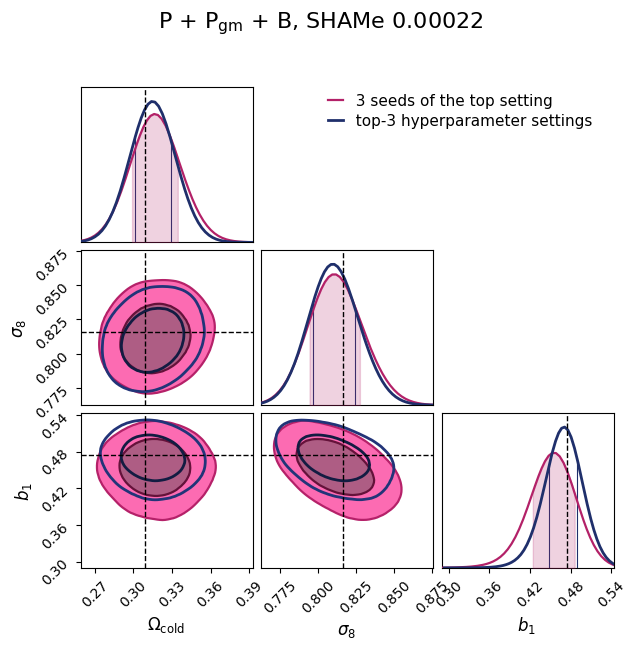

  3 seeds bias/σ: omega_cold=+0.52, sigma8_cold=-0.28, b1=-0.78 | σ: omega_cold=0.0159, sigma8_cold=0.0150, b1=0.0278
  top-3  bias/σ: omega_cold=+0.44, sigma8_cold=-0.39, b1=-0.25 | σ: omega_cold=0.0139, sigma8_cold=0.0141, b1=0.0221


In [6]:
import matplotlib.colors as mcolors
TAG_MOCK16 = "_nbar0.00022"
TRUTH16 = {k: float(v) for k, v in data_loader.load_params_ood("shame", TAG_MOCK16).items() if k in KEY3}
print("SHAMe truth:", {k: round(v, 3) for k, v in TRUTH16.items()})

def load_shame16(stats, masks, member):
    d = r16_dir(stats, masks, member)
    f = d / f"samples_test_shame_{stats}{masks}{TAG_MOCK16}_pred.npy"
    if not f.exists():
        return None
    s = np.load(f)
    s = s[:, 0, :] if s.ndim == 3 else s
    return to_key3(s, np.loadtxt(d / "param_names.txt", dtype=str))

for lab, (st, mk) in R16_COMBOS.items():
    ens = {e: [load_shame16(st, mk, m) for m in members] for e, members in R16_MEMBERS.items()}
    missing = {e: [m or "top" for m, a in zip(R16_MEMBERS[e], arrs) if a is None] for e, arrs in ens.items()}
    if any(missing.values()):
        print(f"{lab}: missing SHAMe samples {missing}"); continue
    mixes = [mix16(ens["3 seeds"]), mix16(ens["top-3 settings"])]
    colors = [R16_COLORS[lab], COLOR_TOP3]
    fig = plotter.plot_contours_inf(
        param_names=KEY3, idx_obs=0, theta_obs_true=None, inf_methods=["sbi"] * 2, tags_inf=["a", "b"],
        tags_test=["", ""], samples_list=[(m, KEY3) for m in mixes],
        labels=["3 seeds of the top setting", "top-3 hyperparameter settings"], colors=colors,
        linestyles=["-", "-"], shades=[True, False], bar_shades=[True, False], linewidths=[1.6, 2.0],
        unreparameterize=False, add_truth=True, truth_locations=[TRUTH16], truth_colors=["k"],
        figsize=(6.5, 6.5), fontsize_legend=11, title=f"{lab}, SHAMe {TAG_MOCK16[5:]}",
        legend_location=(0, 1), legend_loc="upper left", loc_legend=(0.35, 1.0), show=False,
    )
    if fig is None:
        continue
    diag = {ax.get_subplotspec().colspan.start: ax for ax in fig.axes
            if ax.get_subplotspec().rowspan.start == ax.get_subplotspec().colspan.start}
    for j in range(3):   # 68% interval of the top-3 mixture, lines stopping at its 1D curve
        ax = diag[j]
        curves = [l for l in ax.get_lines() if len(l.get_xdata()) > 10
                  and np.allclose(mcolors.to_rgba(l.get_color())[:3], mcolors.to_rgba(COLOR_TOP3)[:3])]
        for q in np.percentile(mixes[1][:, j], [16, 84]):
            y_top = np.interp(q, curves[0].get_xdata(), curves[0].get_ydata()) if curves else ax.get_ylim()[1]
            ax.vlines(q, 0, y_top, color=COLOR_TOP3, lw=0.8)
    fig.savefig(FIG_DIR / f"contours_shame_rand16_ens_{st}.pdf", bbox_inches="tight")
    plt.show()
    # (mean − truth)/σ and σ per mixture
    for e, mx in zip(("3 seeds", "top-3"), mixes):
        dev = [(mx[:, j].mean() - TRUTH16[k]) / mx[:, j].std() for j, k in enumerate(KEY3)]
        print(f"  {e:6s} bias/σ: " + ", ".join(f"{k}={v:+.2f}" for k, v in zip(KEY3, dev))
              + " | σ: " + ", ".join(f"{k}={mx[:, j].std():.4f}" for j, k in enumerate(KEY3)))


## B. Scale cuts

Needs the shared setup only. Each subsection starts with its own setup cell: B1 (k_max grid), B2 (kpgm slice), B3 (kb slice; also used by B4).

### B1. k_max grid: figure of bias on the SHAMe mock

The top sweep setting (`best-rand16`, seed 0, one network, not an ensemble) is retrained at each cut with the same hyperparameters. k_max^{P_gg} is fixed at 0.37. For P+P_gm+B we vary k_max^{P_gm} and k_max^B over the full K_CUTS grid (9 × 9). P+B and P+P_gm vary their single extra cut. Configs come from `code_auxiliary/make_kmax_grid_rand16.py`.

The figure of bias is FoB = $\sqrt{\Delta^T C^{-1} \Delta}$ in physical (Ω_c, σ8, b1). Δ is posterior mean − truth, and C is the posterior covariance, computed from unreparameterized samples. FoB is divided by $\sqrt{\chi^2_3(68.3\%)}$, so 1 is the 1σ contour in 3D, as in paper Fig 8. We use the SHAMe mock truth at each n̄. The phase-matched mean (our forward model on the SHAMe initial conditions, mean of 10 realizations) has the same truth. It isolates the forward-model prior-volume / network part of the bias from the SHAMe-vs-our-model mismatch, so SHAMe FoB well above matched FoB means model mismatch.

- **B1a:** heatmap over (k_max^B, k_max^{P_gm}) for P+P_gm+B. Rows are SHAMe and phase-matched mean, columns are n̄. Grey cells are not done yet. The box marks the old fiducial (0.24, 0.24).
- **B1b:** 1D slices, as in paper Fig 8 (9-10 / 11-15 paper notebooks): k_max^B with k_max^{P_gm} = 0.24, k_max^{P_gm} with k_max^B = 0.24, and joint k_max^B = k_max^{P_gm}. Shades are n̄ (light → dark = 1.1, 2.2, 5.4 × 10⁻⁴). Combos that don't depend on the swept cut are horizontal lines. P alone (kp0.37) is the thin line.

**Caveat:** each point is one network. Seed-to-seed scatter in FoB is not small, so judge trends, not single points. The point at the sweep cuts (kpgm0.24 / kb0.24) is the sweep trial itself. Every other point is a retrain with the same hyperparameters.

In [ ]:
# B1 setup: k_max grid loaders and FoB
K_GRID = [0.11, 0.15, 0.18, 0.21, 0.24, 0.27, 0.31, 0.34, 0.37]
K_FID_OLD = 0.24
TAIL_K = "_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16"
K_COMBOS = {   # label: (stats tag, uses kpgm, uses kb, color)
    "P": ("pk", False, False, plotter_figs.COLORS_FID[0]),
    "P + P$_{\\rm gm}$": ("pk_pgm", True, False, plotter_figs.COLORS_FID[1]),
    "P + B": ("pk_bispec", False, True, plotter_figs.COLORS_FID[2]),
    "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", True, True, plotter_figs.COLORS_FID[3]),
}

def kgrid_tag(stats, kpgm=None, kb=None):
    return f"{stats}_kp0.37" + ("" if kpgm is None else f"_kpgm{kpgm:.2f}") + ("" if kb is None else f"_kb{kb:.2f}")

def kgrid_samples(stats, kpgm, kb, nbar, mock):
    sm = kgrid_tag(stats, kpgm, kb)
    d = DIR_SBI / f"sbi_muchisimocks_{sm}{TAIL_K}"
    if mock == "shame":
        f = d / f"samples_test_shame_{sm}_nbar{nbar}_pred.npy"
    else:
        f = d / (f"samples_test_muchisimocks_{sm}_shamematched{nbar}_p0_n10_biasshame{nbar}"
                 "_noisebest_p0_n1_noisematched_mean_pred.npy")
    if not f.exists():
        return None
    s = np.load(f)
    return (s[:, 0, :] if s.ndim == 3 else s), list(np.loadtxt(d / "param_names.txt", dtype=str))

_fob_cache = {}
def fob3(stats, kpgm, kb, nbar, mock="shame"):
    """FoB(Ω_c, σ8, b1) / sqrt(chi2_3(68%)); NaN if the test isn't done."""
    key = (stats, kpgm, kb, nbar, mock)
    if key not in _fob_cache:
        r = kgrid_samples(stats, kpgm, kb, nbar, mock)
        if r is None:
            _fob_cache[key] = np.nan
        else:
            mu, cov, names = utils_inference.physical_moments_from_samples(*r)
            idx = [list(names).index(p) for p in FOB_PARAMS]
            diff = mu[idx] - TRUTH_K[nbar]
            _fob_cache[key] = float(np.sqrt(diff @ np.linalg.solve(cov[np.ix_(idx, idx)], diff))) / REF3
    return _fob_cache[key]

def combo_fob(label, k_pgm, k_b, nbar, mock):
    """FoB for a combo at cuts (k_pgm, k_b); cuts a combo doesn't use are ignored."""
    stats, use_pgm, use_b, _ = K_COMBOS[label]
    return fob3(stats, k_pgm if use_pgm else None, k_b if use_b else None, nbar, mock)

grid_fob = {(mock, nb): np.array([[combo_fob("P + P$_{\\rm gm}$ + B", kp, kb, nb, mock) for kb in K_GRID]
                                  for kp in K_GRID]) for mock in MOCK_LABS for nb in NBARS}
for (mock, nb), g in grid_fob.items():
    print(f"P+Pgm+B {MOCK_LABS[mock]:20s} nbar {nb}: {np.isfinite(g).sum()}/{g.size} grid points done")

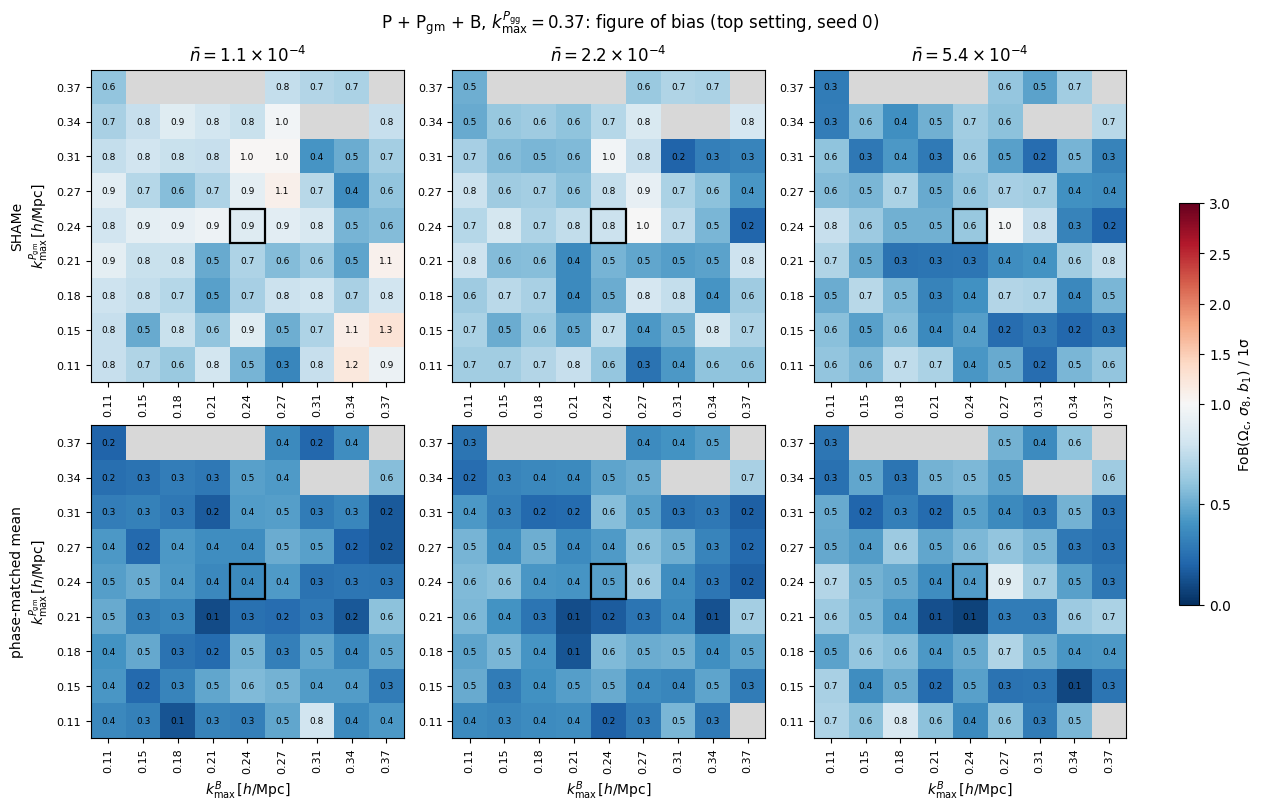

In [8]:
# B1a. P+P_gm+B FoB over the (k_max^B, k_max^{P_gm}) grid
norm = mcolors.Normalize(vmin=0, vmax=3)   # light (unbiased) -> dark red (FoB >= 3)
cmap = plt.get_cmap("Reds").copy()
cmap.set_bad("0.85")
fig, axes = plt.subplots(len(MOCK_LABS), len(NBARS), figsize=(4.2 * len(NBARS), 4.0 * len(MOCK_LABS)),
                         squeeze=False, constrained_layout=True)
i_fid = K_GRID.index(K_FID_OLD)
for r, mock in enumerate(MOCK_LABS):
    for c, nb in enumerate(NBARS):
        ax, g = axes[r, c], grid_fob[(mock, nb)]
        im = ax.imshow(np.ma.masked_invalid(g), origin="lower", cmap=cmap, norm=norm, aspect="equal")
        for i in range(len(K_GRID)):
            for j in range(len(K_GRID)):
                if np.isfinite(g[i, j]):
                    ax.text(j, i, f"{g[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                            color="w" if g[i, j] > 1.8 else "k")
        ax.add_patch(Rectangle((i_fid - 0.5, i_fid - 0.5), 1, 1, fill=False, ec="k", lw=1.6))
        ax.set_xticks(range(len(K_GRID)), [f"{k:.2f}" for k in K_GRID], rotation=90, fontsize=8)
        ax.set_yticks(range(len(K_GRID)), [f"{k:.2f}" for k in K_GRID], fontsize=8)
        if r == len(MOCK_LABS) - 1:
            ax.set_xlabel(r"$k_{\rm max}^{B}\,[h/{\rm Mpc}]$")
        if c == 0:
            ax.set_ylabel(f"{MOCK_LABS[mock]}\n" + r"$k_{\rm max}^{P_{\rm gm}}\,[h/{\rm Mpc}]$")
        if r == 0:
            ax.set_title(NBAR_LABS[nb])
fig.colorbar(im, ax=axes, shrink=0.6, label=r"FoB($\Omega_{\rm c}$, $\sigma_8$, $b_1$) / 1σ")
fig.suptitle(r"P + P$_{\rm gm}$ + B, $k_{\rm max}^{P_{\rm gg}}=0.37$: figure of bias (top setting, seed 0)")
fig.savefig(FIG_DIR / "kmax_grid_fob_pk_pgm_bispec.pdf", bbox_inches="tight")
plt.show()

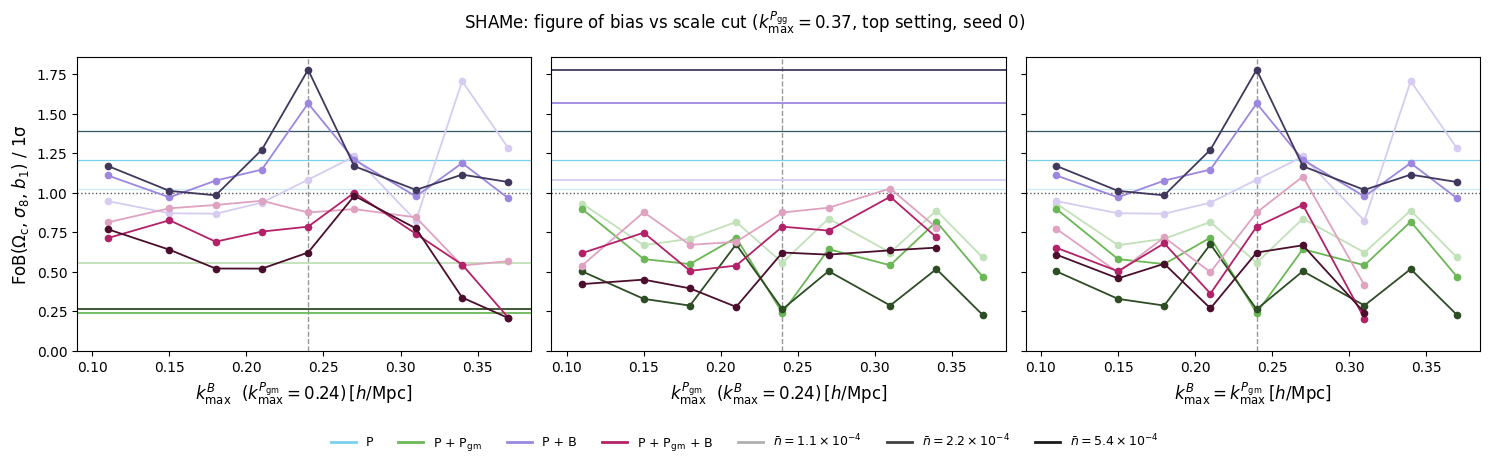

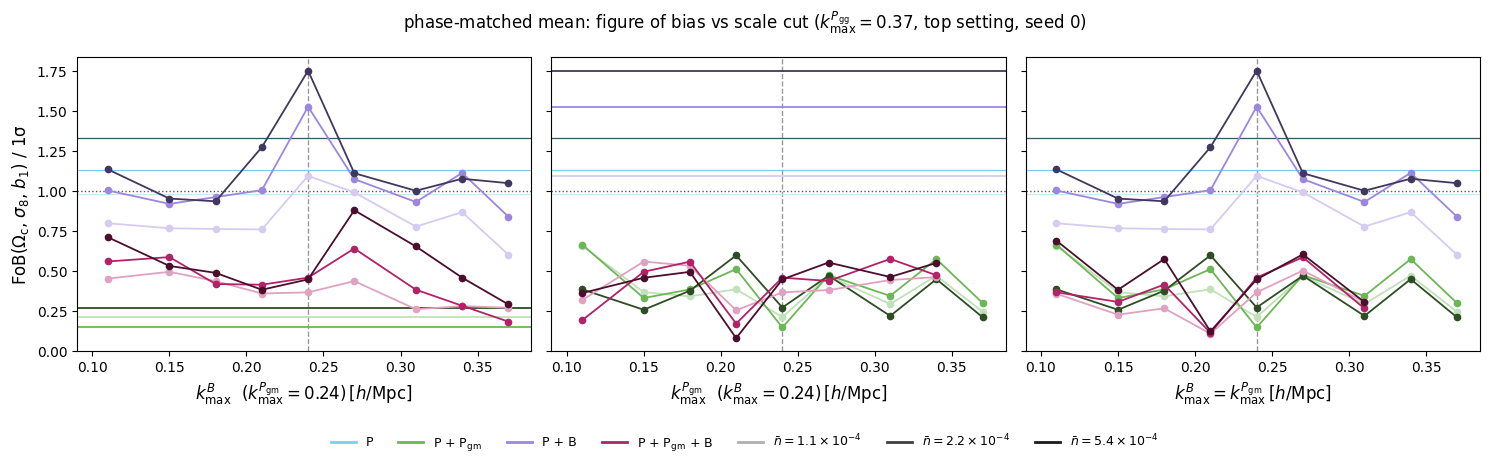

In [9]:
# B1b. 1D slices (paper Fig 8 layout): FoB vs one cut, the other fixed at the old fiducial 0.24
SLICES = [   # (x label, function k -> (k_pgm, k_b) for the swept cut, which combos vary along it)
    (r"$k_{\rm max}^{B}$  ($k_{\rm max}^{P_{\rm gm}}=0.24$)", lambda k: (K_FID_OLD, k), {"P + B", "P + P$_{\\rm gm}$ + B"}),
    (r"$k_{\rm max}^{P_{\rm gm}}$  ($k_{\rm max}^{B}=0.24$)", lambda k: (k, K_FID_OLD), {"P + P$_{\\rm gm}$", "P + P$_{\\rm gm}$ + B"}),
    (r"$k_{\rm max}^{B} = k_{\rm max}^{P_{\rm gm}}$", lambda k: (k, k), {"P + B", "P + P$_{\\rm gm}$", "P + P$_{\\rm gm}$ + B"}),
]

def plot_kmax_slices(mock):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
    for ax, (xlab, cuts, varying) in zip(axes, SLICES):
        for lab, (_, _, _, color) in K_COMBOS.items():
            shades = plotter_figs._nbar_shades(color)
            for j, nb in enumerate(NBARS):
                lab_j = lab if nb == "0.00022" else None
                if lab in varying:
                    y = np.array([combo_fob(lab, *cuts(k), nb, mock) for k in K_GRID])
                    ok = np.isfinite(y)
                    ax.plot(np.array(K_GRID)[ok], y[ok], "-o", color=shades[j], lw=1.3, ms=4.5, label=lab_j, zorder=3)
                else:   # independent of the swept cut: value at the old fiducial
                    v = combo_fob(lab, K_FID_OLD, K_FID_OLD, nb, mock)
                    if np.isfinite(v):
                        ax.axhline(v, color=shades[j], lw=0.9 if lab == "P" else 1.3, label=lab_j, zorder=2)
        ax.axhline(1.0, color="0.35", ls=":", lw=1.0, zorder=0)
        ax.axvline(K_FID_OLD, color="0.6", ls="--", lw=1.0, zorder=0)
        ax.set_xlim(0.09, 0.385)
        ax.set_xlabel(xlab + r"$\,[h/{\rm Mpc}]$", fontsize=12)
    axes[0].set_ylabel(r"FoB($\Omega_{\rm c}$, $\sigma_8$, $b_1$) / 1σ", fontsize=12)
    axes[0].set_ylim(bottom=0)
    h_stat = [Line2D([0], [0], color=c, lw=2) for (_, _, _, c) in K_COMBOS.values()]
    grey = plotter_figs._nbar_shades("0.25")
    h_nbar = [Line2D([0], [0], color=grey[j], lw=2) for j in range(3)]
    fig.legend(h_stat + h_nbar, list(K_COMBOS) + [NBAR_LABS[n] for n in NBARS], fontsize=9, frameon=False,
               loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=7)
    fig.suptitle(f"{MOCK_LABS[mock]}: figure of bias vs scale cut ($k_{{\\rm max}}^{{P_{{\\rm gg}}}}=0.37$, top setting, seed 0)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kmax_slices_fob_{mock}.pdf", bbox_inches="tight")
    plt.show()

for mock in MOCK_LABS:
    plot_kmax_slices(mock)

In [10]:
# numbers behind B1b at the fiducial n̄: FoB per combo along each slice (NaN = not done)
SLICE_NAMES = dict(zip([sl[0] for sl in SLICES], ["kb (kpgm=0.24)", "kpgm (kb=0.24)", "kb = kpgm"]))
COMBO_PLAIN = dict(zip(K_COMBOS, ["P", "P+Pgm", "P+B", "P+Pgm+B"]))
rows = []
for xlab, cuts, varying in SLICES:
    for lab in varying:
        for mock in MOCK_LABS:
            rows.append({"slice": SLICE_NAMES[xlab], "combo": COMBO_PLAIN[lab],
                         "mock": mock, **{k: combo_fob(lab, *cuts(k), "0.00022", mock) for k in K_GRID}})
pd.DataFrame(rows).set_index(["slice", "combo", "mock"]).T.round(2).rename_axis("k_max")

slice kb (kpgm=0.24)                       kpgm (kb=0.24)                \
combo        P+Pgm+B           P+B                P+Pgm+B         P+Pgm   
mock           shame matched shame matched          shame matched shame   
k_max                                                                     
0.11            0.71    0.56  1.11    1.00           0.62    0.19  0.90   
0.15            0.82    0.58  0.97    0.92           0.75    0.49  0.58   
0.18            0.69    0.42  1.08    0.96           0.50    0.56  0.55   
0.21            0.75    0.41  1.15    1.00           0.54    0.17  0.72   
0.24            0.78    0.46  1.56    1.53           0.78    0.46  0.24   
0.27            1.00    0.64  1.21    1.07           0.76    0.44  0.64   
0.31            0.74    0.38  0.98    0.93           0.97    0.57  0.54   
0.34            0.54    0.28  1.19    1.11           0.72    0.47  0.82   
0.37            0.21    0.18  0.96    0.84            NaN     NaN  0.47   

slice         kb = kpgm                                      
combo           P+Pgm+B           P+B         P+Pgm          
mock  matched     shame matched shame matched shame matched  
k_max                                                        
0.11     0.66      0.65    0.36  1.11    1.00  0.90    0.66  
0.15     0.33      0.50    0.30  0.97    0.92  0.58    0.33  
0.18     0.38      0.68    0.41  1.08    0.96  0.55    0.38  
0.21     0.51      0.36    0.11  1.15    1.00  0.72    0.51  
0.24     0.14      0.78    0.46  1.56    1.53  0.24    0.14  
0.27     0.47      0.92    0.58  1.21    1.07  0.64    0.47  
0.31     0.34      0.20    0.26  0.98    0.93  0.54    0.34  
0.34     0.57       NaN     NaN  1.19    1.11  0.82    0.57  
0.37     0.30       NaN     NaN  0.96    0.84  0.47    0.30

#### B1c. Overall k_max: marginal FoM (paper Fig 9, top model only)

Paper Fig 9 (`plotter_figs.plot_fig9_scale_dependence_overall_kmax_fom3_nbars`) with `k_members=1`: the top setting, seed 0, retrained at each overall cut (`make_overall_kmax_rand16.py`). Marginal FoM of Ω_c, σ8 and b1 on SHAMe at the 3 densities (shades). For k_max ≤ 0.24 every statistic is cut at k_max; above it only P_gg continues, with B and P_gm held at 0.24 (dashed line), so those points assume the 0.24 fiducial stands. Missing points are listed below the figure.

SAVE_FIGURES: True
FIG_DIR: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks
FIG_DIR_LATEST: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks
OVERWRITE_FIGURES: True
FIG_EXT: pdf


MISSING FoM | overall kmax ensemble | param=omega_m | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.21 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_nbar0.00011_pred.npy
MISSING FoM | overall kmax ensemble | param=omega_m | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.24 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_nbar0.00011_pred.npy
MISSING FoM | overall kmax ensemble | param=omega_m | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.34 | member 0: missing /sc

MISSING FoM | overall kmax ensemble | param=omega_m | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00054 | k=0.21 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_nbar0.00054_pred.npy
MISSING FoM | overall kmax ensemble | param=omega_m | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00054 | k=0.24 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_nbar0.00054_pred.npy
MISSING FoM | overall kmax ensemble | param=omega_m | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00054 | k=0.34 | member 0: missing /sc

MISSING FoM | overall kmax ensemble | param=sigma8 | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.21 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_nbar0.00011_pred.npy
MISSING FoM | overall kmax ensemble | param=sigma8 | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.24 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_nbar0.00011_pred.npy
MISSING FoM | overall kmax ensemble | param=sigma8 | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.34 | member 0: missing /scrat

MISSING FoM | overall kmax ensemble | param=b1 | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.21 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.21_kpgm0.21_kb0.21_nbar0.00011_pred.npy
MISSING FoM | overall kmax ensemble | param=b1 | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.24 | member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.24_kpgm0.24_kb0.24_nbar0.00011_pred.npy
MISSING FoM | overall kmax ensemble | param=b1 | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | _nbar0.00011 | k=0.34 | member 0: missing /scratch/kstoreyf/

Saved: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks/fig9_overall_kmax_fom_nbars_topmodel.pdf


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks/fig9_overall_kmax_fom_nbars_topmodel.pdf


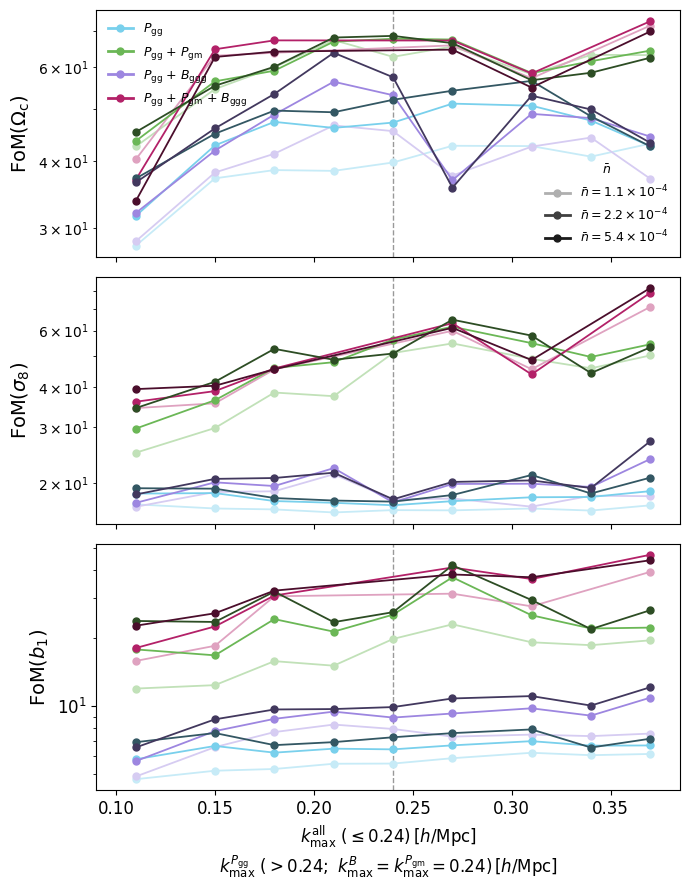

In [11]:
# B1c: Fig 9, top model only
import plotter_figs as pf
pf.configure_figures(save=True, fig_dir=FIG_DIR, fig_dir_latest=FIG_DIR, ext="pdf")
pf.plot_fig9_scale_dependence_overall_kmax_fom3_nbars(
    k_members=1, save_name="fig9_overall_kmax_fom_nbars_topmodel", report_missing=True)


### B2. Moving to $k_{\rm max}^{P_{\rm gm}}=0.37$: do the fiducial hyperparameters transfer, and is the top-3 ensemble sound along the slice?

All for the full combo P+P$_{\rm gm}$+B, $k_{\rm max}^{P_{gg}}=0.37$, launched 2026-11-21. Needs the shared setup and the B2 setup cell.

**Question 1: hyperparameter transfer (B2a).** The hyperparameters come from one sweep at (kpgm0.24, kb0.24). The data vector at other cuts differs a lot (50 bispectrum elements at kb0.24, vs 7 at kb0.11 and 161 at kb0.37). New `-rand16` sweeps were run at (kpgm0.37, kb0.11), (kpgm0.37, kb0.24) and (kpgm0.37, kb0.37). The fiducial top-3 settings were retrained at the same cuts (`code_auxiliary/make_kpgm37_checks_rand16.py`, edgectrl list).

*Rule, fixed before the sweeps finished:* the fiducial settings transfer if the best edge-sweep trial's val NLL is no more than max(2 × spread of the 3 fiducial settings, 0.15) nats below the best of the 3 settings. Coverage must also be sane. SHAMe FoB is deliberately *not* used, since that would be circular with the kpgm choice.

**Question 2: ensemble health along the kpgm slice (B2b).** For kb0.24 and every kpgm in K_CUTS, all 3 fiducial settings are trained (seed 0). Setting 1 is the k_max grid model. The equal-weight top-3 mixture is the planned fiducial ensemble. A member that failed to train would make the mixture too broad at that cut, so each member is checked against the best one at its cut.

In [ ]:
# B2 setup: best validation loss of every model in the kpgm0.37 tests, parsed from the training logs
# (each log names its train config; the last "best" in the newest log for a config is that model's best val loss).
# The 3 fiducial-cut models (kpgm0.24, kb0.24) are sweep trials copied into best-mode dirs: they have no train log,
# so they come from the A1 sweep table (ranks 1–3 of the P+P_gm+B sweep = best_runs.txt lines 0–2).
KB_EDGES6, KPGM_NEW6, KB_FID6 = (0.11, 0.24, 0.37), 0.37, 0.24
PRE6 = "pk_pgm_bispec_kp0.37_kpgm{}_kb{}_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16"

vl_logs = {}
for g in ("train_kmaxgrid_rand16-*.out", "train_kpgmslice_ens_rand16-*.out", "train_edgectrl_rand16-*.out",
          "train_slice_retrain_rand16-*.out", "train_kpgm24_retrain_rand16-*.out"):
    vl_logs.update(train_log_table(g))
_fid_sweep = df_sweeps["P + P$_{\\rm gm}$ + B"]
for i, m in enumerate(SETTINGS6):   # fiducial cut: the sweep trials themselves
    vl_logs[PRE6.format(0.24, 0.24) + m] = {"best_val_loss": _fid_sweep["best_val_loss"][i],
                                           "n_epochs": _fid_sweep["n_epochs"][i], "done": bool(_fid_sweep["done"][i])}

def vl6(kpgm, kb, member):
    r = vl_logs.get(PRE6.format(kpgm, kb) + member)
    return (np.nan, False) if r is None else (r["best_val_loss"], r["done"])

# the three new sweeps at kpgm0.37
df_edge_sweeps = {kb: sweep_trials(f"sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.37_kb{kb}") for kb in KB_EDGES6}



In [ ]:
# B2a. Do the fiducial-sweep hyperparameters transfer to other k_max^B?  (P+P_gm+B, kp0.37, kpgm0.37)
# Everything is relative to the best of the 3 fiducial settings at that cut (Δ = 0; lower = better).
# Rule (agreed before the sweeps ran): transfer OK if the best edge-sweep trial is no more than
# max(2 × spread of the 3 settings, 0.15) nats below the best setting. Spread = max − min of the 3 settings.
YLIM6 = (-0.75, 1.0)

edge_rows = []
fig, ax = plt.subplots(figsize=(8.5, 5.4))
rng = np.random.default_rng(1)
for x, kb in enumerate(KB_EDGES6):
    fid = {lab: vl6(KPGM_NEW6, kb, m) for m, lab in SETTINGS6.items()}
    v_fid = np.array([v for v, _ in fid.values()])
    best_fid, spread = np.nanmin(v_fid), np.nanmax(v_fid) - np.nanmin(v_fid)
    thr = max(2 * spread, 0.15)
    d = df_edge_sweeps[kb]
    dv = d["best_val_loss"].values - best_fid
    best_sweep = dv.min()
    passes = best_sweep >= -thr

    # allowed region: from 0 down to -threshold
    ax.add_patch(plt.Rectangle((x - 0.42, -thr), 0.84, thr, color="0.92", zorder=0))
    ax.hlines(-thr, x - 0.42, x + 0.42, color="0.45", ls="--", lw=1, zorder=1)
    # sweep trials (grey), off-scale ones counted at the top
    on = dv <= YLIM6[1]
    jit = rng.uniform(-0.12, 0.12, len(dv))
    done = d["done"].values
    ax.scatter((x - 0.18 + jit)[on & done], dv[on & done], s=26, color="0.55", zorder=2)
    ax.scatter((x - 0.18 + jit)[on & ~done], dv[on & ~done], s=26, facecolor="none", edgecolor="0.55", zorder=2)
    if (~on).sum():
        ax.annotate(f"+{(~on).sum()} worse trials\n(off scale)", (x - 0.18, YLIM6[1]), xytext=(0, -4),
                    textcoords="offset points", ha="center", va="top", fontsize=7, color="0.4")
    # the 3 fiducial settings
    for j, (lab, (v, dn)) in enumerate(fid.items()):
        ax.scatter(x + 0.14 + 0.09 * j, v - best_fid, s=55, marker=MARKERS6[lab], zorder=3,
                   color=COLORS6[lab] if dn else "none", edgecolor=COLORS6[lab], lw=1.5)
    ax.text(x, YLIM6[0] + 0.03, ("PASS" if passes else "FAIL") + f"\nbest sweep {best_sweep:+.2f} vs limit {-thr:.2f}",
            ha="center", va="bottom", fontsize=8, color="0.15", fontweight="bold" if not passes else None)
    edge_rows.append({"kb": kb, "n_trials": len(d), "n_trials_done": int(done.sum()),
                      **{lab: v for lab, (v, _) in fid.items()}, "spread_3settings": spread,
                      "best_sweep": d["best_val_loss"].min(), "Δ best sweep vs best setting": best_sweep,
                      "limit": -thr, "pass": passes,
                      "best sweep hparams": "/".join(str(d.iloc[0][k]) for k in HP_KEYS)})

ax.axhline(0, color="0.3", lw=0.8, zorder=1)
ax.set_xticks(range(len(KB_EDGES6)))
ax.set_xticklabels([f"$k_{{\\rm max}}^B={kb}$" + ("\n(candidate fiducial)" if kb == KB_FID6 else "\n(edge)")
                    for kb in KB_EDGES6])
ax.set_xlim(-0.55, len(KB_EDGES6) - 0.45)
ax.set_ylim(*YLIM6)
ax.set_ylabel("best val. NLL − best of the 3 fiducial settings  [nats]\n(lower = better)")
handles = [Line2D([], [], ls="", marker="o", color="0.55", label="edge-sweep trial (rand16)"),
           Line2D([], [], ls="", marker="o", mfc="none", mec="0.55", label="edge-sweep trial, still training")]
handles += [Line2D([], [], ls="", marker=MARKERS6[l], color=c, ms=7, label=f"fiducial {l}") for l, c in COLORS6.items()]
handles += [plt.Rectangle((0, 0), 1, 1, color="0.92", label="allowed: within max(2×spread, 0.15)")]
ax.legend(handles=handles, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
ax.set_title("Hyperparameter transfer across $k_{\\rm max}^B$  (P+P$_{\\rm gm}$+B, $k_{\\rm max}^{P_{\\rm gm}}=0.37$)",
             fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "kpgm037_hparam_transfer_edges.pdf", bbox_inches="tight")
plt.show()
df_edge = pd.DataFrame(edge_rows)
df_edge.round(3)

In [ ]:
# B2b. kpgm slice (kb0.24): do all 3 settings train comparably at every k_max^{P_gm}?
# Left: absolute val NLL (each cut has its own data vector, so only the comparison within a cut means anything).
# Right: each member relative to the best member at that cut. The grey band is the seed-to-seed scatter of the
# top setting at the fiducial cut (pure network noise); the dashed line is the retrain threshold (0.4 nats, agreed
# 2026-11-22): a member above it is a failed training and is retrained with seed 1 (stars, once their logs exist;
# code_auxiliary/make_kpgm37_checks_rand16.py, slice_retrain_rand16 list). Δ for a star is vs the same best member.

sl = pd.DataFrame([{"kpgm": k, "member": lab, "val": vl6(k, KB_FID6, m)[0], "done": vl6(k, KB_FID6, m)[1]}
                   for k in K_SLICE6 for m, lab in SETTINGS6.items()])
sl["Δ vs best member"] = sl["val"] - sl.groupby("kpgm")["val"].transform("min")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
off = {"setting 1": -0.004, "setting 2": 0.0, "setting 3": 0.004}
for lab in SETTINGS6.values():
    s = sl[sl["member"] == lab]
    for ax, col in zip(axes, ("val", "Δ vs best member")):
        ax.plot(s["kpgm"] + off[lab], s[col], "-", color=COLORS6[lab], lw=1.2, alpha=0.6)
        ax.scatter((s["kpgm"] + off[lab])[s["done"]], s[col][s["done"]], marker=MARKERS6[lab],
                   color=COLORS6[lab], s=40, zorder=3, label=lab)
        ax.scatter((s["kpgm"] + off[lab])[~s["done"]], s[col][~s["done"]], marker=MARKERS6[lab],
                   facecolor="none", edgecolor=COLORS6[lab], s=40, zorder=3)
ax = axes[1]
ax.axhspan(0, SEED_SCATTER6, color="0.9", zorder=0, label=f"seed scatter, fiducial cut ({SEED_SCATTER6:.2f})")
ax.axhline(RETRAIN_THR6, color="0.35", ls="--", lw=1, label=f"retrain threshold ({RETRAIN_THR6})")
RETRAIN_SUFFIX6 = "_seed1"
best_by_k = sl.groupby("kpgm")["val"].min()
for _, r in sl[sl["Δ vs best member"] > RETRAIN_THR6].iterrows():
    m = {lab: m for m, lab in SETTINGS6.items()}[r["member"]]
    v, dn = vl6(r["kpgm"], KB_FID6, m + RETRAIN_SUFFIX6)
    if np.isfinite(v):
        ax.scatter(r["kpgm"] + off[r["member"]], v - best_by_k[r["kpgm"]], marker="*", s=110, zorder=4,
                   color=COLORS6[r["member"]] if dn else "none", edgecolor=COLORS6[r["member"]])
        ax.annotate("", (r["kpgm"], v - best_by_k[r["kpgm"]]), xytext=(r["kpgm"], r["Δ vs best member"]),
                    arrowprops=dict(arrowstyle="->", color="0.5", lw=0.8))
for _, r in sl[sl["Δ vs best member"] > RETRAIN_THR6].iterrows():
    ax.annotate("retrain", (r["kpgm"], r["Δ vs best member"]), xytext=(6, 0), textcoords="offset points",
                fontsize=7.5, va="center", color="0.25")
missing = sl[sl["val"].isna()]
for _, r in missing.iterrows():
    ax.annotate("training", (r["kpgm"], 0), xytext=(0, -14), textcoords="offset points", ha="center",
                fontsize=6.5, color=COLORS6[r["member"]])
axes[0].set_ylabel("best validation NLL  [nats]")
axes[1].set_ylabel("val. NLL − best member at this cut  [nats]")
for ax in axes:
    ax.set_xlabel(r"$k_{\rm max}^{P_{\rm gm}}$  [$h$/Mpc]   ($k_{\rm max}^B=0.24$)")
    ax.set_xticks(K_SLICE6)
    ax.tick_params(axis="x", labelsize=8)
    for k in (0.24, 0.37):   # current fiducial, candidate
        ax.axvline(k, color="0.75", lw=0.8, ls=":", zorder=0)
axes[0].legend(fontsize=8, frameon=False)
axes[1].legend(fontsize=7.5, frameon=False, loc="upper left")
axes[1].set_ylim(-0.05, max(1.15, sl["Δ vs best member"].max() + 0.1))
fig.suptitle("Top-3 ensemble members along the $k_{\\rm max}^{P_{\\rm gm}}$ slice (P+P$_{\\rm gm}$+B; "
             "open = still training)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "kpgm037_slice_members_val_nll.pdf", bbox_inches="tight")
plt.show()
sl.pivot(index="kpgm", columns="member", values="Δ vs best member").round(3)

#### B2c. FoB along the kpgm slice with the top-3 ensemble

This is the kpgm decision. It shows P+P$_{\rm gm}$+B FoB on SHAMe (top) and the phase-matched mean (bottom) vs $k_{\rm max}^{P_{\rm gm}}$ at kb0.24, for the 3 densities. Needs the B2 cells above (B2a–B2b).
- **Solid line:** the equal-weight top-3 mixture.
- **Dashed line:** the mixture without the members flagged in B2b. This approximates the retrained ensemble.
- **Faint markers:** the individual members, so the network scatter that the mixture averages over is visible.

A second figure shows the constraining power (FoM in Ω_c, σ8, b1) of the mixture relative to kpgm0.24.

In [ ]:
# B2c. FoB along the kpgm slice (kb0.24) with the top-3 ensemble: the actual kpgm decision.
# Uses B1 (TRUTH_K, NBARS, NBAR_LABS, MOCK_LABS, FOB_PARAMS, REF3) and B2b (sl, RETRAIN_THR6, COLORS6, MARKERS6).
# Faint markers: the 3 members (settings 1-3, seed 0). Solid line: equal-weight top-3 mixture (needs all 3 members).
# Dashed line: the members flagged in B2b (val NLL > RETRAIN_THR6 above the best member at that cut) replaced by
# their seed-1 retrain; until a retrain's test is done that member is left out instead (printed below).
def member_samples6(kpgm, member, nbar, mock):
    sm = f"pk_pgm_bispec_kp0.37_kpgm{kpgm:.2f}_kb{KB_FID6:.2f}"
    d = DIR_SBI / f"sbi_muchisimocks_{PRE6.format(f'{kpgm:.2f}', f'{KB_FID6:.2f}')}{member}"
    if mock == "shame":
        f = d / f"samples_test_shame_{sm}_nbar{nbar}_pred.npy"
    else:
        f = d / (f"samples_test_muchisimocks_{sm}_shamematched{nbar}_p0_n10_biasshame{nbar}"
                 "_noisebest_p0_n1_noisematched_mean_pred.npy")
    if not f.exists():
        return None
    s = np.load(f)
    return (s[:, 0, :] if s.ndim == 3 else s), list(np.loadtxt(d / "param_names.txt", dtype=str))

flagged6 = {(r["kpgm"], r["member"]) for _, r in sl.iterrows() if r["Δ vs best member"] > RETRAIN_THR6}
fob_rows = []
retrain_used6 = {}   # (kpgm, member) -> retrain used (True) or member left out (False)
for mock in MOCK_LABS:
    for nb in NBARS:
        for k in K_SLICE6:
            rs = {lab: member_samples6(k, m, nb, mock) for m, lab in SETTINGS6.items()}
            for lab, r in rs.items():
                if r is not None:
                    fob_rows.append({"mock": mock, "nbar": nb, "kpgm": k, "model": lab, **dict(zip(("FoB", "FoM"), fob_and_fom6(*r, nb)))})
            if all(r is not None for r in rs.values()):
                fob_rows.append({"mock": mock, "nbar": nb, "kpgm": k, "model": "top-3 mixture",
                                 **dict(zip(("FoB", "FoM"), fob_and_fom6(*mix6(list(rs.values())), nb)))})
                keep = []
                for m, lab in SETTINGS6.items():
                    if (k, lab) not in flagged6:
                        keep.append(rs[lab])
                    else:
                        rr = member_samples6(k, m + RETRAIN_SUFFIX6, nb, mock)
                        if rr is not None:
                            keep.append(rr)
                        retrain_used6[(k, lab)] = rr is not None
                fob_rows.append({"mock": mock, "nbar": nb, "kpgm": k, "model": "mixture w/o flagged",
                                 **dict(zip(("FoB", "FoM"), fob_and_fom6(*mix6(keep), nb)))})
# kpgm0.24: the members above are the sweep trials themselves (val-loss winners); "fresh" = seed 1 of each setting
# (setting 1 seed 1 = the A2 3-seed model; settings 2, 3 seed 1 from make_kpgm37_checks_rand16.py), on equal footing
# with the retrained networks at the other cuts.
FRESH6 = ["_seed1", "_nbest1_seed1", "_nbest2_seed1"]
for mock in MOCK_LABS:
    for nb in NBARS:
        rs = [member_samples6(0.24, m, nb, mock) for m in FRESH6]
        if all(r is not None for r in rs):
            fob_rows.append({"mock": mock, "nbar": nb, "kpgm": 0.24, "model": "top-3 mixture, fresh (seed 1)",
                             **dict(zip(("FoB", "FoM"), fob_and_fom6(*mix6(rs), nb)))})
df_fob6 = pd.DataFrame(fob_rows)
print("flagged members in the dashed mixture:", {k: ("seed-1 retrain" if v else "left out (retrain not done)")
                                                 for k, v in sorted(retrain_used6.items())})

COLOR_MIX6 = plotter_figs.COLORS_FID[3]   # paper color for P+P_gm+B
fig, axes = plt.subplots(len(MOCK_LABS), len(NBARS), figsize=(4.3 * len(NBARS), 3.6 * len(MOCK_LABS)),
                         sharex=True, sharey=True, squeeze=False)
for i, mock in enumerate(MOCK_LABS):
    for j, nb in enumerate(NBARS):
        ax = axes[i, j]
        d = df_fob6[(df_fob6["mock"] == mock) & (df_fob6["nbar"] == nb)]
        for lab in SETTINGS6.values():
            s = d[d["model"] == lab]
            ax.scatter(s["kpgm"] + off[lab], s["FoB"], marker=MARKERS6[lab], s=22, color=COLORS6[lab], alpha=0.45,
                       lw=0, zorder=2)
            fl = s[[(k, lab) in flagged6 for k in s["kpgm"]]]   # flagged members: ringed
            ax.scatter(fl["kpgm"] + off[lab], fl["FoB"], marker=MARKERS6[lab], s=70, facecolor="none",
                       edgecolor="0.2", lw=0.9, zorder=2)
        for model, ls in (("top-3 mixture", "-"), ("mixture w/o flagged", "--")):
            s = d[d["model"] == model]
            ax.plot(s["kpgm"], s["FoB"], ls, marker="o" if ls == "-" else None, ms=5, color=COLOR_MIX6, lw=2 if ls == "-" else 1.3,
                    zorder=3)
        fr = d[d["model"] == "top-3 mixture, fresh (seed 1)"]
        ax.scatter(fr["kpgm"], fr["FoB"], marker="D", s=55, facecolor="white", edgecolor=COLOR_MIX6, lw=1.8, zorder=4)
        ax.axhline(1.0, color="0.35", ls=":", lw=1, zorder=0)
        for k in (0.24, 0.37):
            ax.axvline(k, color="0.75", lw=0.8, ls=":", zorder=0)
        if i == 0:
            ax.set_title(NBAR_LABS[nb], fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{MOCK_LABS[mock]}\nFoB($\\Omega_{{\\rm c}}$, $\\sigma_8$, $b_1$) / 1σ")
        if i == len(MOCK_LABS) - 1:
            ax.set_xlabel(r"$k_{\rm max}^{P_{\rm gm}}$  [$h$/Mpc]   ($k_{\rm max}^B=0.24$)")
            ax.set_xticks(K_SLICE6)
            ax.tick_params(axis="x", labelsize=7.5)
axes[0, 0].set_ylim(bottom=0)
handles = [Line2D([], [], color=COLOR_MIX6, lw=2, marker="o", ms=5, label="top-3 mixture"),
           Line2D([], [], color=COLOR_MIX6, lw=1.3, ls="--", label=f"mixture, flagged members (B2b) retrained / left out if not done")]
handles += [Line2D([], [], ls="", marker=MARKERS6[l], color=c, alpha=0.6, label=f"member: {l}") for l, c in COLORS6.items()]
handles += [Line2D([], [], ls="", marker="o", mfc="none", mec="0.2", ms=8, label="flagged member"),
            Line2D([], [], ls="", marker="D", mfc="white", mec=COLOR_MIX6, mew=1.8, ms=7,
                   label="kpgm0.24: fresh top-3 (seed 1), not the sweep trials")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=8, frameon=False)
fig.suptitle("P+P$_{\\rm gm}$+B figure of bias along the $k_{\\rm max}^{P_{\\rm gm}}$ slice: top-3 ensemble", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "kpgm037_slice_fob_top3.pdf", bbox_inches="tight")
plt.show()

# constraining power of the mixture on SHAMe, relative to the FRESH kpgm0.24 ensemble (fair baseline: every point is
# then a retrained network); open markers at 0.24 = the sweep-trial ensemble, which the line used before.
_sh = df_fob6[df_fob6["mock"] == "shame"]
mixfom = _sh[_sh["model"] == "top-3 mixture"].pivot(index="kpgm", columns="nbar", values="FoM")
fresh_fom = _sh[_sh["model"] == "top-3 mixture, fresh (seed 1)"].set_index("nbar")["FoM"]
if len(fresh_fom) == len(NBARS):
    mixfom.loc[0.24, :] = fresh_fom[mixfom.columns].values
    sweep_fom24 = _sh[(_sh["model"] == "top-3 mixture") & (_sh["kpgm"] == 0.24)].set_index("nbar")["FoM"]
    print("FoM at kpgm0.24, sweep-trial ensemble / fresh ensemble:", (sweep_fom24 / fresh_fom).round(2).to_dict())
else:
    sweep_fom24 = None
    print("fresh kpgm0.24 ensemble not complete: baseline = sweep-trial ensemble")
fom_ratio = mixfom / mixfom.loc[0.24]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
shades = plotter_figs._nbar_shades(COLOR_MIX6)
for j, nb in enumerate(NBARS):
    ax.plot(fom_ratio.index, fom_ratio[nb], "-o", ms=4.5, color=shades[j], label=NBAR_LABS[nb])
    if sweep_fom24 is not None:
        ax.scatter(0.24, sweep_fom24[nb] / mixfom.loc[0.24, nb], marker="o", s=40, facecolor="none",
                   edgecolor=shades[j], zorder=3)
ax.axhline(1, color="0.35", ls=":", lw=1)
for k in (0.24, 0.37):
    ax.axvline(k, color="0.75", lw=0.8, ls=":", zorder=0)
ax.set_xlabel(r"$k_{\rm max}^{P_{\rm gm}}$  [$h$/Mpc]   ($k_{\rm max}^B=0.24$)")
ax.set_ylabel("FoM($\\Omega_{\\rm c}$, $\\sigma_8$, $b_1$) / FoM at $k_{\\rm max}^{P_{\\rm gm}}=0.24$ (fresh)")
ax.set_xticks(K_SLICE6); ax.tick_params(axis="x", labelsize=7.5)
ax.legend(fontsize=8, frameon=False)
ax.set_title("SHAMe, top-3 mixture: gain from larger $k_{\\rm max}^{P_{\\rm gm}}$", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "kpgm037_slice_fom_top3.pdf", bbox_inches="tight")
plt.show()

df_fob6[df_fob6["model"].isin(["top-3 mixture", "mixture w/o flagged"])].pivot_table(
    index="kpgm", columns=["mock", "nbar", "model"], values="FoB").round(2)

**Findings (2026-11-22; coverage and slice FoB still to come).**
- *B2a, transfer: passes at all three cuts.*
  - kb0.11: the best sweep trial is 0.18 nats better than the best fiducial setting; the limit is 0.44.
  - kb0.24: the best sweep trial is 0.16 nats better; the limit is 0.30.
  - kb0.37: the fiducial setting 2 beats all 16 sweep trials.
  - The best sweep trial is a different setting at each cut (512/8/3e-5/64, 512/10/1e-4/256, 256/8/3e-4/256). The gaps are the size of the spread among the 3 fiducial settings and of the seed scatter (0.20 at the fiducial cut). Within the lr ≈ 1e-4 family, val NLL is flat across hyperparameters. The data-vector size does not call for different hyperparameters.
- *B2b, slice:*
  - Settings 1 and 2 track each other everywhere, within the seed scatter.
  - Setting 3 (256/8/1e-4/256) is 0.6–1.0 nats worse at kpgm 0.18, 0.21 and 0.27. That is 3–5× the seed scatter, so it is a failed training, not a real preference. At kpgm0.34 it is the best member.
  - **Decided 2026-11-22:** a member > 0.4 nats above the best member at its cut is a failed training. It is retrained with seed 1 (job 8120288), which replaces it in the mixture; this is reported in the appendix. The kpgm0.24 members (sweep winners) also get seed-1 retrains of settings 2 and 3 (job 8120285), to remove the winner's-curse baseline.
- *B2c, FoB along the slice:*
  - The top-3 mixture is below 1σ everywhere on SHAMe: 0.6–0.74 at $\bar n=1.1\times10^{-4}$, 0.46–0.69 at 2.2, 0.12–0.56 at 5.4. There is no trend up to kpgm0.37; at 0.37 it is 0.70 / 0.52 / 0.26.
  - The phase-matched mean is ≤ 0.46 throughout, so the SHAMe residual is mostly model mismatch, roughly constant with kpgm.
  - Dropping the flagged setting-3 members changes the mixture FoB by ≤ 0.15, at 0.21 and 0.27 only. The retrain question does not change the bias conclusion.
  - Individual members scatter by up to ±0.3 around the mixture, the same scatter that made the B1 grid unreadable.
- *Constraining power:*
  - FoM(Ω_c, σ8, b1) of the mixture rises steeply up to kpgm0.24, then is flat or noisy: about 0.85–1.04× the 0.24 value from 0.27 to 0.37, and lower at $\bar n=5.4\times10^{-4}$.
  - Caveat: at kpgm0.24 all 3 members are the sweep trials themselves, chosen on val loss. The networks at every other cut are retrained. The 0.24 baseline is therefore probably flattered by the winner's curse, as for the P+B kb0.24 point in B1.
- **Reading:** kpgm0.37 is safe for bias, but on this evidence it buys little constraining power over 0.24. To test that fairly, the 0.24 point needs retrained members (e.g. seeds 1 of each setting), not the sweep winners.
- To add: coverage at the edges and at kpgm0.37 (inner500).

### B3. $k_{\rm max}^B$ slice with top-3 ensembles: choosing the fiducial bispectrum cut

Launched 2026-11-22 (`code_auxiliary/make_kbslice_top3_rand16.py`), $k_{\rm max}^{P_{gg}}=0.37$ throughout. Needs the shared setup only; the B3 setup cell is also the setup for B4.
- **P+P$_{\rm gm}$+B** at the new fiducial $k_{\rm max}^{P_{\rm gm}}=0.37$, with the top 3 of the kpgm0.37/kb0.24 sweep (`_best-rand16-topkpgm0.37`).
- **P+B** with the top 3 of its own sweep (kb0.24, unchanged).

Every point is a fresh training. At the sweep cut kb0.24 the members are seed 1 of each setting. The sweep-trial ensemble there (the selected winners) is the open circle.

The 0.4-nat failed-member rule from B2 is applied: failed members are ringed and listed, and the dashed line leaves them out. Mixtures appear only once all 3 members' tests are done.

B3a shows FoB on SHAMe and the phase-matched mean. B3b shows FoM relative to the fresh kb0.24 mixture, plus the val-NLL health check.

In [ ]:
# B3: k_max^B slice with top-3 ensembles (code_auxiliary/make_kbslice_top3_rand16.py), kp0.37 throughout.
# B3 / B4 setup. Needs the shared setup only.
#   P+P_gm+B at kpgm0.37: top 3 of the kpgm0.37/kb0.24 sweep (_best-rand16-topkpgm0.37[_nbest{n}])
#   P+B: top 3 of the P+B sweep (kb0.24; _best-rand16[_nbest{n}]); setting 1 at kb != 0.24 = the k_max grid model
# Every point is a fresh training: at the sweep cut kb0.24 the members are seed 1 of each setting; the sweep-trial
# ensemble there (the selected winners) is drawn as an open circle for reference.
# Failed members: val NLL > RETRAIN_THR6 above the best member at that cut (rule agreed 2026-11-22) -> ringed, and the
# dashed line leaves them out (retrains to be queued).
KB7_SWEEP = 0.24
TAIL7 = "_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000"
KB_COMBOS7 = {   # label: (stats tag, masks(kb), best tag, color)
    "P + B": ("pk_bispec", lambda kb: f"_kp0.37_kb{kb:.2f}", "_best-rand16", plotter_figs.COLORS_FID[2]),
    "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", lambda kb: f"_kp0.37_kpgm0.37_kb{kb:.2f}", "_best-rand16-topkpgm0.37",
                              plotter_figs.COLORS_FID[3]),
}
SET_SUFFIX7 = {"setting 1": "", "setting 2": "_nbest1", "setting 3": "_nbest2"}

def members7(kb, fresh=True):
    """setting -> dir suffix after the best tag. kb0.24: seed 1 (fresh) or seed 0 (= the sweep trials)."""
    seed = "_seed1" if (kb == KB7_SWEEP and fresh) else ""
    return {lab: suf + seed for lab, suf in SET_SUFFIX7.items()}

def dir7(combo, kb, member):
    st, mk, best, _ = KB_COMBOS7[combo]
    return DIR_SBI / f"sbi_muchisimocks_{st}{mk(kb)}{TAIL7}{best}{member}"

def samples7(combo, kb, member, nbar, mock):
    st, mk, _, _ = KB_COMBOS7[combo]
    sm = f"{st}{mk(kb)}"
    d = dir7(combo, kb, member)
    f = (d / f"samples_test_shame_{sm}_nbar{nbar}_pred.npy" if mock == "shame" else
         d / f"samples_test_muchisimocks_{sm}_shamematched{nbar}_p0_n10_biasshame{nbar}_noisebest_p0_n1_noisematched_mean_pred.npy")
    if not f.exists():
        return None
    s = np.load(f)
    return (s[:, 0, :] if s.ndim == 3 else s), list(np.loadtxt(d / "param_names.txt", dtype=str))

# val NLL per member from the training logs (kb slice, k_max grid, A2 seeds); sweep trials from the sweep tables
vl7 = {}
for g in ("train_kmaxgrid_rand16-*.out", "train_kbslice_top3_*.out", "train_v2_bestseeds_*.out",
          "train_kbslice_retrain_rand16-*.out", "train_ppb_nbest2_rand16-*.out"):   # newest log per model wins
    vl7.update(train_log_table(g))
_sw7 = {"P + B": df_sweeps["P + B"],
        "P + P$_{\\rm gm}$ + B": sweep_trials("sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.37_kb0.24")}
def val7(combo, kb, member):
    st, mk, best, _ = KB_COMBOS7[combo]
    r = vl7.get(f"{st}{mk(kb)}{TAIL7}{best}{member}")
    if r is not None:
        return r["best_val_loss"], r["done"]
    if kb == KB7_SWEEP and member in SET_SUFFIX7.values():   # seed 0 at the sweep cut = sweep trial (rank order)
        i = list(SET_SUFFIX7.values()).index(member)
        return _sw7[combo]["best_val_loss"][i], True
    return np.nan, False

rows7 = []
for combo in KB_COMBOS7:
    for kb in K_SLICE6:
        for lab, m in members7(kb).items():
            v, dn = val7(combo, kb, m)
            rows7.append({"combo": combo, "kb": kb, "member": lab, "suffix": m, "val": v, "done": dn})
vl7_df = pd.DataFrame(rows7)
vl7_df["Δ vs best member"] = vl7_df["val"] - vl7_df.groupby(["combo", "kb"])["val"].transform("min")
flag7 = vl7_df[vl7_df["Δ vs best member"] > RETRAIN_THR6]
print("failed members (val NLL > %.1f above best at that cut; partly-trained members can still improve):" % RETRAIN_THR6)
print(flag7[["combo", "kb", "member", "suffix", "val", "Δ vs best member", "done"]].round(3).to_string(index=False)
      if len(flag7) else "  none")
flag7_set = {(r.combo, r.kb, r.member) for r in flag7.itertuples()}

# FoB / FoM per member and per mixture
fob7 = []
for combo in KB_COMBOS7:
    for mock in MOCK_LABS:
        for nb in NBARS:
            for kb in K_SLICE6:
                rs = {lab: samples7(combo, kb, m, nb, mock) for lab, m in members7(kb).items()}
                base = {"combo": combo, "mock": mock, "nbar": nb, "kb": kb}
                for lab, r in rs.items():
                    if r is not None:
                        fob7.append({**base, "model": lab, **dict(zip(("FoB", "FoM"), fob_and_fom6(*r, nb)))})
                if all(r is not None for r in rs.values()):
                    fob7.append({**base, "model": "top-3 mixture", **dict(zip(("FoB", "FoM"), fob_and_fom6(*mix6(list(rs.values())), nb)))})
                    keep = [r for lab, r in rs.items() if (combo, kb, lab) not in flag7_set]
                    fob7.append({**base, "model": "mixture w/o failed", **dict(zip(("FoB", "FoM"), fob_and_fom6(*mix6(keep), nb)))})
                if kb == KB7_SWEEP:
                    rsw = [samples7(combo, kb, m, nb, mock) for m in members7(kb, fresh=False).values()]
                    if all(r is not None for r in rsw):
                        fob7.append({**base, "model": "sweep-trial mixture", **dict(zip(("FoB", "FoM"), fob_and_fom6(*mix6(rsw), nb)))})
fob7 = pd.DataFrame(fob7)
print("kb points with a complete top-3 mixture (of 9):", fob7[(fob7["model"] == "top-3 mixture")].groupby("combo")["kb"].nunique().to_dict())

In [ ]:
# B3a. FoB vs k_max^B: top-3 mixtures (lines), members (faint), failed members ringed
off7 = {"setting 1": -0.004, "setting 2": 0.0, "setting 3": 0.004}
fig, axes = plt.subplots(len(MOCK_LABS), len(NBARS), figsize=(4.3 * len(NBARS), 3.6 * len(MOCK_LABS)),
                         sharex=True, sharey=True, squeeze=False)
for i, mock in enumerate(MOCK_LABS):
    for j, nb in enumerate(NBARS):
        ax = axes[i, j]
        for combo, (_, _, _, color) in KB_COMBOS7.items():
            d = fob7[(fob7["combo"] == combo) & (fob7["mock"] == mock) & (fob7["nbar"] == nb)]
            for lab in SET_SUFFIX7:
                s = d[d["model"] == lab]
                ax.scatter(s["kb"] + off7[lab], s["FoB"], marker=MARKERS6[lab], s=18, color=color, alpha=0.3, lw=0, zorder=2)
                fl = s[np.array([(combo, k, lab) in flag7_set for k in s["kb"]], dtype=bool)]
                ax.scatter(fl["kb"] + off7[lab], fl["FoB"], marker=MARKERS6[lab], s=65, facecolor="none",
                           edgecolor="0.2", lw=0.9, zorder=2)
            for model, ls in (("top-3 mixture", "-"), ("mixture w/o failed", "--")):
                s = d[d["model"] == model]
                ax.plot(s["kb"], s["FoB"], ls, marker="o" if ls == "-" else None, ms=4.5, color=color,
                        lw=2 if ls == "-" else 1.2, zorder=3)
            s = d[d["model"] == "sweep-trial mixture"]
            ax.scatter(s["kb"], s["FoB"], marker="o", s=60, facecolor="none", edgecolor=color, lw=1.5, zorder=4)
        ax.axhline(1.0, color="0.35", ls=":", lw=1, zorder=0)
        ax.axvline(KB7_SWEEP, color="0.75", lw=0.8, ls=":", zorder=0)
        if i == 0:
            ax.set_title(NBAR_LABS[nb], fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{MOCK_LABS[mock]}\nFoB($\\Omega_{{\\rm c}}$, $\\sigma_8$, $b_1$) / 1σ")
        if i == len(MOCK_LABS) - 1:
            ax.set_xlabel(r"$k_{\rm max}^{B}$  [$h$/Mpc]")
            ax.set_xticks(K_SLICE6)
            ax.tick_params(axis="x", labelsize=7.5)
axes[0, 0].set_ylim(bottom=0)
handles = [Line2D([], [], color=c, lw=2, marker="o", ms=5, label=f"{lab}: top-3 mixture")
           for lab, (_, _, _, c) in KB_COMBOS7.items()]
handles += [Line2D([], [], color="0.3", lw=1.2, ls="--", label="mixture w/o failed members"),
            Line2D([], [], ls="", marker="o", mfc="none", mec="0.3", mew=1.5, ms=8,
                   label="kb0.24 sweep-trial mixture (selected winners)"),
            Line2D([], [], ls="", marker="o", mfc="none", mec="0.2", ms=8, label="failed member (ringed)")]
handles += [Line2D([], [], ls="", marker=MARKERS6[l], color="0.4", alpha=0.5, label=f"member: {l}") for l in SET_SUFFIX7]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=8, frameon=False)
fig.suptitle("Figure of bias vs $k_{\\rm max}^B$, top-3 ensembles ($k_{\\rm max}^{P_{gg}}=0.37$; "
             "P+P$_{\\rm gm}$+B at $k_{\\rm max}^{P_{\\rm gm}}=0.37$, new hyperparameters)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "kbslice_fob_top3.pdf", bbox_inches="tight")
plt.show()

# B3b. constraining power vs kb (SHAMe), relative to the fresh kb0.24 mixture; and the val-NLL health check
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, combo in zip(axes[:2], KB_COMBOS7):
    color = KB_COMBOS7[combo][3]
    sh = fob7[(fob7["combo"] == combo) & (fob7["mock"] == "shame")]
    mf = sh[sh["model"] == "top-3 mixture"].pivot(index="kb", columns="nbar", values="FoM")
    shades = plotter_figs._nbar_shades(color)
    if KB7_SWEEP in mf.index:
        for j, nb in enumerate(NBARS):
            ax.plot(mf.index, mf[nb] / mf.loc[KB7_SWEEP, nb], "-o", ms=4.5, color=shades[j], label=NBAR_LABS[nb])
            sw = sh[(sh["model"] == "sweep-trial mixture") & (sh["nbar"] == nb)]["FoM"]
            if len(sw):
                ax.scatter(KB7_SWEEP, sw.iloc[0] / mf.loc[KB7_SWEEP, nb], s=40, facecolor="none", edgecolor=shades[j], zorder=3)
    ax.axhline(1, color="0.35", ls=":", lw=1)
    ax.axvline(KB7_SWEEP, color="0.75", lw=0.8, ls=":", zorder=0)
    ax.set_title(f"{combo}: FoM (SHAMe) / fresh kb0.24 mixture", fontsize=10)
    ax.set_xlabel(r"$k_{\rm max}^{B}$  [$h$/Mpc]"); ax.set_xticks(K_SLICE6); ax.tick_params(axis="x", labelsize=7.5)
    ax.legend(fontsize=7.5, frameon=False)
axes[0].set_ylabel("FoM($\\Omega_{\\rm c}$, $\\sigma_8$, $b_1$) ratio\n(open = sweep-trial mixture at kb0.24)")
ax = axes[2]
for combo, (_, _, _, color) in KB_COMBOS7.items():
    for lab in SET_SUFFIX7:
        s = vl7_df[(vl7_df["combo"] == combo) & (vl7_df["member"] == lab)]
        ax.scatter((s["kb"] + off7[lab])[s["done"]], s["Δ vs best member"][s["done"]], marker=MARKERS6[lab], s=30, color=color)
        ax.scatter((s["kb"] + off7[lab])[~s["done"]], s["Δ vs best member"][~s["done"]], marker=MARKERS6[lab], s=30,
                   facecolor="none", edgecolor=color)
ax.axhspan(0, SEED_SCATTER6, color="0.9", zorder=0)
ax.axhline(RETRAIN_THR6, color="0.35", ls="--", lw=1)
ax.set_title("val. NLL − best member at that cut (open = still training)", fontsize=10)
ax.set_xlabel(r"$k_{\rm max}^{B}$  [$h$/Mpc]"); ax.set_xticks(K_SLICE6); ax.tick_params(axis="x", labelsize=7.5)
ax.set_ylabel("[nats]")
fig.tight_layout()
fig.savefig(FIG_DIR / "kbslice_fom_valnll_top3.pdf", bbox_inches="tight")
plt.show()

fob7[fob7["model"].isin(["top-3 mixture", "sweep-trial mixture"]) & (fob7["mock"] == "shame")].pivot_table(
    index="kb", columns=["combo", "nbar", "model"], values="FoB").round(2)

**Status (2026-11-22, partial):** P+B has 7 of 9 kb points complete; P+P$_{\rm gm}$+B has 2 of 9, the rest still training.
- **P+B:**
  - SHAMe FoB is ≈ 0.9–1.2 at *every* kb, including kb0.11 (7 elements).
  - The phase-matched mean is also ≈ 0.8–1.1.
  - So P+B's ~1σ offset is not driven by small-scale bispectrum mismatch. It is there with the forward model's own phases too (prior/projection or network, not model mismatch). To investigate.
- **P+P$_{\rm gm}$+B:** 0.67 / 0.60 / 0.37 at kb0.24 (fresh) on SHAMe.
- **Failed members so far:** P+B setting 2 (seed 1) at kb0.24, P+B setting 1 at kb0.31 (the grid model), P+P$_{\rm gm}$+B setting 3 at kb0.37. Retrains not queued yet.
- **Winner's curse is not consistent in sign:** the P+B sweep-trial mixture at kb0.24 has *higher* FoM than fresh (1.17–1.37×); the P+P$_{\rm gm}$+B one has *lower* (0.69–0.76×).

### B4. Is the SHAMe FoB test strong enough? SHAMe vs phase-matched shifts along the $k_{\rm max}^B$ slice

The SHAMe FoB in B3 is nearly flat in $k_{\rm max}^B$, though other work finds the bias model good only to $k\approx0.25$. The absolute FoB is a weak test, for two reasons:
1. **A common offset.** It carries an offset that is also present in the phase-matched mock, generated with our own model. That offset is mostly prior/projection effects, which is why adding P$_{\rm gm}$ reduces it. It also carries the SHAMe box's own cosmic variance.
2. **Possibly little added information.** It says nothing where the extra modes don't tighten the posterior.

This section uses the same top-3 fresh mixtures as B3. Failed members are swapped for their retrain, or dropped if no retrain exists (printed by the setup cell).

- **B4a. SHAMe − phase-matched shift in (Ω_c, σ8, b1).**
  - The 10 matched realizations share SHAMe's phases. They differ only in the noise field and are generated at the SHAMe-fitted bias and noise.
  - So the shift SHAMe vs matched$_i$ = model mismatch + noise-realization difference. Cosmic variance and the common offset cancel.
  - The null, matched$_i$ vs matched$_j$, is the noise-realization difference alone.
  - Model breakdown shows up as the colored band leaving the grey one as $k_{\rm max}^B$ grows.
- **B4b. Per-parameter signed shift, for all inferred parameters.** A breakdown can be absorbed by $b_2$, $b_{s^2}$, $b_{\nabla^2}$ or the noise amplitudes while cosmology stays put.
- **B4c. Does the test have power?** FoB vs FoM gain, with $k_{\rm max}^B$ along each curve. A flat FoB only means something where the curve moves right.

In [ ]:
# B4 setup: SHAMe vs phase-matched shifts along the kb slice. Needs the shared setup and the B3 setup cell.
# The 10 phase-matched realizations share the SHAMe phases (and pair-fixed 0/pi) and differ only in the noise field
# (eps seeds 40000+i), generated with our forward model at the SHAMe-fitted bias + noise. So
#   SHAMe vs matched_i   = model mismatch + noise-realization difference
#   matched_i vs matched_j = noise-realization difference only  (the null)
# and cosmic variance and any common offset (prior/projection, network bias) cancel in both.
import itertools

PHYS9 = ["omega_cold", "sigma8_cold", "b1", "b2", "bs2", "bl", "An_homog", "An_b1", "An_b2", "An_bs2", "An_bl"]
PLAB9 = {"omega_cold": r"$\Omega_{\rm c}$", "sigma8_cold": r"$\sigma_8$", "b1": "$b_1$", "b2": "$b_2$",
         "bs2": r"$b_{s^2}$", "bl": r"$b_{\nabla^2}$", "An_homog": r"$A_n$", "An_b1": r"$A_n^{b_1}$",
         "An_b2": r"$A_n^{b_2}$", "An_bs2": r"$A_n^{b_{s^2}}$", "An_bl": r"$A_n^{b_{\nabla^2}}$"}
# failed members (B3, 0.4-nat rule) -> their retrain; if the retrain's tests aren't done the member is left out
RETRAIN9 = {("P + B", 0.24, "setting 2"): "_nbest1_seed2",
            ("P + B", 0.31, "setting 1"): "_seed1",
            ("P + P$_{\\rm gm}$ + B", 0.37, "setting 3"): "_nbest2_seed1"}
TRUTH9_MATCHED = {nb: pd.read_csv(REPO_ROOT / "data" / "params" / f"params_fixed_biasshame{nb}_noisebest_p0_n1.txt").iloc[0]
                  for nb in NBARS}   # what the matched mocks were generated with (SHAMe cosmology below)
COSMO9 = {"omega_cold": float(TRUTH_K[NBARS[0]][0]), "sigma8_cold": float(TRUTH_K[NBARS[0]][1])}

def post9(combo, kb, member, nbar, kind):
    """(n_draws, n_obs, n_params) reparameterized samples + names. kind: shame (1 obs) | matched (10 obs)."""
    st, mk, _, _ = KB_COMBOS7[combo]
    sm, d = f"{st}{mk(kb)}", dir7(combo, kb, member)
    f = (d / f"samples_test_shame_{sm}_nbar{nbar}_pred.npy" if kind == "shame" else
         d / f"samples_test_muchisimocks_{sm}_shamematched{nbar}_p0_n10_biasshame{nbar}_noisebest_p0_n1_noisematched_pred.npy")
    if not f.exists():
        return None
    s = np.load(f)
    return (s if s.ndim == 3 else s[:, None, :]), list(np.loadtxt(d / "param_names.txt", dtype=str))

def members9(combo, kb):
    """setting -> suffix: B3's fresh members, failed ones swapped for their retrain (or dropped if not done)."""
    out, note = {}, []
    for lab, m in members7(kb).items():
        if (combo, kb, lab) in RETRAIN9:
            r = RETRAIN9[(combo, kb, lab)]
            if all(post9(combo, kb, r, nb, k) is not None for nb in NBARS for k in ("shame", "matched")):
                out[lab] = r; note.append(f"{lab}->{r}")
            else:
                note.append(f"{lab} dropped")
        elif (combo, kb, lab) not in flag7_set:
            out[lab] = m
        else:
            note.append(f"{lab} dropped (flagged, no retrain listed)")
    return out, note

def moments9(rs, obs):
    """Physical mean, cov of the equal-weight mixture of members rs (list of post9 outputs) for observation obs."""
    mu, cov, nm = utils_inference.physical_moments_from_samples(*mix6([(s[:, obs, :], n) for s, n in rs]))
    idx = [list(nm).index(p) for p in PHYS9 if p in nm]
    return mu[idx], cov[np.ix_(idx, idx)], [nm[i] for i in idx]

rows9, notes9 = [], {}
for combo in KB_COMBOS7:
    for kb in K_SLICE6:
        mem, note = members9(combo, kb)
        if note:
            notes9[(combo, kb)] = note
        for nb in NBARS:
            rs_s = [post9(combo, kb, m, nb, "shame") for m in mem.values()]
            rs_m = [post9(combo, kb, m, nb, "matched") for m in mem.values()]
            if len(mem) < 2 or any(r is None for r in rs_s + rs_m):
                continue
            mu_s, c_s, nm = moments9(rs_s, 0)
            mus_m = np.array([moments9(rs_m, i)[0] for i in range(rs_m[0][0].shape[1])])
            rows9.append({"combo": combo, "kb": kb, "nbar": nb, "n_members": len(mem), "names": nm,
                          "mu_shame": mu_s, "cov_shame": c_s, "mu_matched": mus_m})
res9 = pd.DataFrame(rows9)
print("member swaps:", {f"{c} kb{k:.2f}": v for (c, k), v in notes9.items()})
print("kb points per combo with SHAMe + all 10 matched done:", res9.groupby("combo")["kb"].nunique().to_dict())

def dist9(d, c3inv):
    return np.sqrt(np.einsum("...i,ij,...j->...", d, c3inv, d)) / REF3

# FoB-type distances in (Ω_c, σ8, b1), all in the SHAMe posterior's metric
fob9 = []
for r in res9.itertuples():
    i3 = [r.names.index(p) for p in FOB_PARAMS]
    cinv = np.linalg.inv(r.cov_shame[np.ix_(i3, i3)])
    m3 = r.mu_matched[:, i3]
    d_sm = dist9(r.mu_shame[i3] - m3, cinv)                                       # 10 values
    d_null = np.array([dist9(m3[i] - m3[j], cinv) for i, j in itertools.combinations(range(len(m3)), 2)])  # 45
    d_mean = float(dist9(r.mu_shame[i3] - m3.mean(0), cinv))
    fob9.append({"combo": r.combo, "kb": r.kb, "nbar": r.nbar, "d_sm": d_sm, "d_null": d_null, "d_mean": d_mean,
                 # expected distance of one draw from the mean of 10 under the null: pairwise / sqrt(2) * sqrt(11/10)
                 "d_mean_null": np.median(d_null) / np.sqrt(2) * np.sqrt(1 + 1 / len(m3))})
fob9 = pd.DataFrame(fob9)

In [ ]:
# B4a. SHAMe vs phase-matched shift in (Ω_c, σ8, b1) along the kb slice, against the noise-only null.
# Line + band: median and 16-84% of the 10 SHAMe-vs-matched_i distances. Grey: the 45 matched_i-vs-matched_j distances.
# Model breakdown = the colored band leaving the grey one as kb grows.
fig, axes = plt.subplots(len(KB_COMBOS7), len(NBARS), figsize=(4.3 * len(NBARS), 3.4 * len(KB_COMBOS7)),
                         sharex=True, sharey=True, squeeze=False)
for i, (combo, (_, _, _, color)) in enumerate(KB_COMBOS7.items()):
    for j, nb in enumerate(NBARS):
        ax = axes[i, j]
        d = fob9[(fob9["combo"] == combo) & (fob9["nbar"] == nb)].sort_values("kb")
        if len(d):
            q = lambda col, p: [np.percentile(v, p) for v in d[col]]
            ax.fill_between(d["kb"], q("d_null", 16), q("d_null", 84), color="0.85", lw=0, zorder=0)
            ax.plot(d["kb"], q("d_null", 50), color="0.55", lw=1.2, zorder=1)
            ax.fill_between(d["kb"], q("d_sm", 16), q("d_sm", 84), color=color, alpha=0.25, lw=0, zorder=2)
            ax.plot(d["kb"], q("d_sm", 50), "-o", ms=4, color=color, lw=2, zorder=3)
        ax.axvline(KB7_SWEEP, color="0.75", lw=0.8, ls=":", zorder=0)
        if i == 0:
            ax.set_title(NBAR_LABS[nb], fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{combo}\nshift($\\Omega_{{\\rm c}}$, $\\sigma_8$, $b_1$) / 1σ$_{{\\rm SHAMe}}$")
        if i == len(KB_COMBOS7) - 1:
            ax.set_xlabel(r"$k_{\rm max}^{B}$  [$h$/Mpc]")
            ax.set_xticks(K_SLICE6); ax.tick_params(axis="x", labelsize=7.5)
axes[0, 0].set_ylim(bottom=0)
handles = [Line2D([], [], color="0.3", lw=2, marker="o", ms=4, label="SHAMe vs matched$_i$ (median, 16–84%)"),
           Line2D([], [], color="0.55", lw=6, alpha=0.4, label="null: matched$_i$ vs matched$_j$ (noise realization only)")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=8.5, frameon=False)
fig.suptitle("SHAMe − phase-matched posterior-mean shift along the $k_{\\rm max}^B$ slice (top-3 mixtures, fresh)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "kbslice_shame_vs_matched_shift.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# B4b. Per-parameter signed shift (μ_SHAMe − mean_i μ_matched,i) / σ_SHAMe, cosmological + bias parameters.
# Grey band: ±1σ of the same quantity for one matched realization vs the mean of the other 9 (noise-only null, at the
# fiducial n̄). Cosmology flat but b2 / bs2 / bl running with kb = the bias model absorbing a breakdown.
shades9 = {c: plotter_figs._nbar_shades(v[3]) for c, v in KB_COMBOS7.items()}
names9 = [p for p in PHYS9 if not p.startswith("An") and (not len(res9) or p in res9["names"].iloc[0])]   # cosmology + bias only
fig, axes = plt.subplots(len(KB_COMBOS7), len(names9), figsize=(2.05 * len(names9), 2.6 * len(KB_COMBOS7)),
                         sharex=True, sharey=True, squeeze=False)
for i, combo in enumerate(KB_COMBOS7):
    r_c = res9[res9["combo"] == combo].sort_values("kb")
    for k, p in enumerate(names9):
        ax = axes[i, k]
        for j, nb in enumerate(NBARS):
            d = r_c[r_c["nbar"] == nb]
            if not len(d):
                continue
            ip = [d["names"].iloc[0].index(p)] * len(d)
            sig = np.array([np.sqrt(c[q, q]) for c, q in zip(d["cov_shame"], ip)])
            sh = np.array([(ms[q] - mm[:, q].mean()) for ms, mm, q in zip(d["mu_shame"], d["mu_matched"], ip)]) / sig
            ax.plot(d["kb"], sh, "-o", ms=3, lw=1.4, color=shades9[combo][j], label=NBAR_LABS[nb])
            if nb == NBARS[1]:   # null spread: leave-one-out matched realization vs mean of the rest
                null = np.array([np.std([mm[a, q] - np.delete(mm[:, q], a).mean() for a in range(len(mm))])
                                 for mm, q in zip(d["mu_matched"], ip)]) / sig
                ax.fill_between(d["kb"], -null, null, color="0.88", lw=0, zorder=0)
        ax.axhline(0, color="0.4", lw=0.8)
        ax.axvline(KB7_SWEEP, color="0.75", lw=0.8, ls=":", zorder=0)
        if i == 0:
            ax.set_title(PLAB9[p], fontsize=11)
        if k == 0:
            ax.set_ylabel(f"{combo}\n(SHAMe − matched) / σ", fontsize=9)
        if i == len(KB_COMBOS7) - 1:
            ax.set_xlabel(r"$k_{\rm max}^{B}$")
            ax.set_xticks([0.11, 0.24, 0.37]); ax.tick_params(axis="x", labelsize=7.5)
axes[0, 0].legend(fontsize=7, frameon=False, loc="best")
fig.suptitle("Per-parameter SHAMe − phase-matched shift vs $k_{\\rm max}^B$ (grey: noise-realization null at "
             f"{NBAR_LABS[NBARS[1]]})", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "kbslice_shame_vs_matched_shift_allparams.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# B4c. Is the test informative? FoB against FoM gain, with kb along each curve. A flat FoB only says something where
# the curve moves to the right (the extra bispectrum modes tighten the posterior). Solid: SHAMe FoB vs truth (includes
# the common projection/prior offset); dashed: SHAMe − matched shift (median of B4a; offset cancels).
REF9 = K_SLICE6[0]
fig, axes = plt.subplots(1, len(NBARS), figsize=(4.6 * len(NBARS), 3.9), sharey=True, squeeze=False)
for j, nb in enumerate(NBARS):
    ax = axes[0, j]
    for combo, (_, _, _, color) in KB_COMBOS7.items():
        d = res9[(res9["combo"] == combo) & (res9["nbar"] == nb)].sort_values("kb")
        if not len(d) or REF9 not in set(d["kb"]):
            continue
        i3 = [d["names"].iloc[0].index(p) for p in FOB_PARAMS]
        c3 = [c[np.ix_(i3, i3)] for c in d["cov_shame"]]
        fom = np.array([1 / np.sqrt(np.linalg.det(c)) for c in c3])
        gain = fom / fom[list(d["kb"]).index(REF9)]
        fob_abs = [float(dist9(m[i3] - TRUTH_K[nb], np.linalg.inv(c))) for m, c in zip(d["mu_shame"], c3)]
        f9 = fob9[(fob9["combo"] == combo) & (fob9["nbar"] == nb)].set_index("kb").loc[d["kb"]]
        ax.plot(gain, fob_abs, "-o", ms=4.5, lw=2, color=color, label=f"{combo}: FoB vs truth")
        ax.plot(gain, [np.median(v) for v in f9["d_sm"]], "--s", ms=3.5, lw=1.2, color=color,
                label=f"{combo}: SHAMe − matched shift")
        for g, y, kb in zip(gain, fob_abs, d["kb"]):
            ax.annotate(f"{kb:.2f}", (g, y), textcoords="offset points", xytext=(3, 4), fontsize=6.5, color=color)
    ax.axhline(1.0, color="0.35", ls=":", lw=1)
    ax.axvline(1.0, color="0.75", lw=0.8, ls=":")
    ax.set_title(NBAR_LABS[nb], fontsize=10)
    ax.set_xlabel(f"FoM($\\Omega_{{\\rm c}}$, $\\sigma_8$, $b_1$) / FoM at $k_{{\\rm max}}^B={REF9}$  (SHAMe)")
axes[0, 0].set_ylabel("distance / 1σ")
axes[0, 0].set_ylim(bottom=0)
_h, _l = axes[0, 0].get_legend_handles_labels()
fig.legend(_h, _l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=8, frameon=False)
fig.suptitle("Does the FoB test have power? FoB vs information gained along the $k_{\\rm max}^B$ slice "
             "(labels: $k_{\\rm max}^B$)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "kbslice_fob_vs_fomgain.pdf", bbox_inches="tight")
plt.show()

pd.DataFrame([{"combo": r.combo, "kb": r.kb, "nbar": r.nbar, "SHAMe−matched (median)": np.median(r.d_sm),
               "null (median)": np.median(r.d_null), "SHAMe − mean(matched)": r.d_mean,
               "null for that": r.d_mean_null} for r in fob9.itertuples()]).pivot_table(
    index="kb", columns=["combo", "nbar"], values=["SHAMe−matched (median)", "null (median)"]).round(2)

#### B4d. Bias per cosmological / bias parameter, and a combined FoB over them except $b_{\nabla^2}$

Truth = SHAMe cosmology plus the SHAMe-fitted bias the phase-matched mocks were generated with. That is the exact truth for the matched mock; for SHAMe the bias values are fits. Noise amplitudes are left out (no SHAMe truth).
- **Per-parameter figures (one per mock):** (μ − truth)/σ for Ω_c, σ8, b1, b2, $b_{s^2}$, $b_{\nabla^2}$. Grey band = ±1σ.
- **Combined FoB:** over (Ω_c, σ8, b1, b2, $b_{s^2}$), normalized by $\sqrt{\chi^2_5(68\%)}$; $b_{\nabla^2}$ is left out (its SHAMe fit is not a reliable truth). Dotted = the usual (Ω_c, σ8, b1) FoB.

In [ ]:
# B4d. Bias per cosmological / bias parameter along the kb slice, and a combined FoB over them except b_∇².
# Truth: SHAMe cosmology + the SHAMe-fitted bias the phase-matched mocks were generated with
# (params_fixed_biasshame{n̄}_noisebest_p0_n1). For the matched mock that is the exact truth; for SHAMe the bias
# values are fits. Noise amplitudes are not shown (no SHAMe truth). b_∇² is shown per parameter but
# left out of the combined FoB (its SHAMe fit is not a reliable truth; the paper figures leave it out too).
# Members as in B4 (failed ones swapped for their retrain or dropped); matched = the mean of the 10 realizations.
PARAMS_D = [p for p in PHYS9 if not p.startswith("An")]          # Ω_c, σ8, b1, b2, bs2, bl
FOB_ALL_PARAMS = [p for p in PARAMS_D if p != "bl"]
REF_ALL = float(np.sqrt(chi2.ppf(0.682689492137, len(FOB_ALL_PARAMS))))

def truth_all(nb):
    return {**COSMO9, **{p: float(TRUTH9_MATCHED[nb][p]) for p in PARAMS_D if p not in COSMO9}}

rows_d = []
for combo in KB_COMBOS7:
    for kb in K_SLICE6:
        mem, _ = members9(combo, kb)
        for nb in NBARS:
            tr = truth_all(nb)
            for mock in MOCK_LABS:
                rs = [samples7(combo, kb, m, nb, mock) for m in mem.values()]
                if len(mem) < 2 or any(r is None for r in rs):
                    continue
                mu, cov, nm = utils_inference.physical_moments_from_samples(*mix6(rs))
                nm = list(nm)
                row = {"combo": combo, "kb": kb, "nbar": nb, "mock": mock}
                for p in PARAMS_D:
                    if p in nm:
                        k = nm.index(p)
                        row[p] = (mu[k] - tr[p]) / np.sqrt(cov[k, k])
                for lab, ps, ref in (("FoB cosmo+bias", FOB_ALL_PARAMS, REF_ALL), ("FoB 3", FOB_PARAMS, REF3)):
                    idx = [nm.index(p) for p in ps]
                    dlt = mu[idx] - np.array([tr[p] for p in ps])
                    row[lab] = float(np.sqrt(dlt @ np.linalg.solve(cov[np.ix_(idx, idx)], dlt))) / ref
                rows_d.append(row)
dfd = pd.DataFrame(rows_d)

# per parameter: one figure per mock; rows = combos, columns = parameters, shades = n̄
for mock in MOCK_LABS:
    fig, axes = plt.subplots(len(KB_COMBOS7), len(PARAMS_D), figsize=(2.2 * len(PARAMS_D), 2.6 * len(KB_COMBOS7)),
                             sharex=True, sharey=True, squeeze=False)
    for i, combo in enumerate(KB_COMBOS7):
        for k, p in enumerate(PARAMS_D):
            ax = axes[i, k]
            for j, nb in enumerate(NBARS):
                d = dfd[(dfd["combo"] == combo) & (dfd["nbar"] == nb) & (dfd["mock"] == mock)].sort_values("kb")
                if len(d) and p in d:
                    ax.plot(d["kb"], d[p], "-o", ms=3, lw=1.4, color=shades9[combo][j], label=NBAR_LABS[nb])
            ax.axhspan(-1, 1, color="0.92", zorder=0)
            ax.axhline(0, color="0.4", lw=0.8)
            ax.axvline(KB7_SWEEP, color="0.75", lw=0.8, ls=":", zorder=0)
            if i == 0:
                ax.set_title(PLAB9[p] + (" (not in FoB)" if p == "bl" else ""), fontsize=10)
            if k == 0:
                ax.set_ylabel(f"{combo}\n(μ − truth) / σ", fontsize=9)
            if i == len(KB_COMBOS7) - 1:
                ax.set_xlabel(r"$k_{\rm max}^{B}$")
                ax.set_xticks([0.11, 0.24, 0.37]); ax.tick_params(axis="x", labelsize=7.5)
    axes[0, 0].legend(fontsize=7, frameon=False, loc="best")
    fig.suptitle(f"{MOCK_LABS[mock]}: bias per parameter vs $k_{{\\rm max}}^B$ (grey: ±1σ)", fontsize=11)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kbslice_bias_per_param_{mock}.pdf", bbox_inches="tight")
    plt.show()

# combined: FoB over all parameters but b_∇² (solid), with the (Ω_c, σ8, b1) FoB for reference (dotted)
fig, axes = plt.subplots(len(MOCK_LABS), len(NBARS), figsize=(4.3 * len(NBARS), 3.4 * len(MOCK_LABS)),
                         sharex=True, sharey=True, squeeze=False)
for i, mock in enumerate(MOCK_LABS):
    for j, nb in enumerate(NBARS):
        ax = axes[i, j]
        for combo, (_, _, _, color) in KB_COMBOS7.items():
            d = dfd[(dfd["combo"] == combo) & (dfd["nbar"] == nb) & (dfd["mock"] == mock)].sort_values("kb")
            ax.plot(d["kb"], d["FoB cosmo+bias"], "-o", ms=4, lw=2, color=color)
            ax.plot(d["kb"], d["FoB 3"], ":", lw=1.3, color=color)
        ax.axhline(1.0, color="0.35", ls=":", lw=1, zorder=0)
        ax.axvline(KB7_SWEEP, color="0.75", lw=0.8, ls=":", zorder=0)
        if i == 0:
            ax.set_title(NBAR_LABS[nb], fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{MOCK_LABS[mock]}\nFoB / 1σ")
        if i == len(MOCK_LABS) - 1:
            ax.set_xlabel(r"$k_{\rm max}^{B}$  [$h$/Mpc]")
            ax.set_xticks(K_SLICE6); ax.tick_params(axis="x", labelsize=7.5)
axes[0, 0].set_ylim(bottom=0)
handles = [Line2D([], [], color=c, lw=2, marker="o", ms=4, label=lab) for lab, (_, _, _, c) in KB_COMBOS7.items()]
handles += [Line2D([], [], color="0.3", lw=2, label="FoB($\\Omega_{\\rm c}$, $\\sigma_8$, $b_1$, $b_2$, $b_{s^2}$)"),
            Line2D([], [], color="0.3", lw=1.3, ls=":", label="FoB($\\Omega_{\\rm c}$, $\\sigma_8$, $b_1$)")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=8.5, frameon=False)
fig.suptitle("Combined figure of bias vs $k_{\\rm max}^B$: cosmology + bias except $b_{\\nabla^2}$", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "kbslice_fob_allparams.pdf", bbox_inches="tight")
plt.show()

dfd.pivot_table(index="kb", columns=["combo", "mock", "nbar"], values="FoB cosmo+bias").round(2)

**Findings (2026-11-23; P+B kb0.24 and P+P$_{\rm gm}$+B kb0.31/0.37 partly missing):**
- **B4a, there is a real SHAMe-vs-model mismatch at low density, flat in $k_{\rm max}^B$ up to 0.31.**
  - At $\bar n=1.1\times10^{-4}$ the shift is ≈0.5σ for both combos, against a null of ≈0.2σ (P+B) and ≈0.3σ (P+P$_{\rm gm}$+B).
  - At $2.2\times10^{-4}$ it is ≈0.3 against 0.15–0.2, a smaller excess.
  - At $5.4\times10^{-4}$ there is no excess.
  - Being flat in kb, this mismatch comes from P (or the low-k bispectrum and the noise model), not from high-k B.
- **P+B, $\bar n=1.1\times10^{-4}$: a breakdown at $k_{\rm max}^B\geq0.34$.** The shift jumps to 1.1–1.3σ. B4b shows it is carried by $b_{\nabla^2}$ (−2.5 to −3.5σ), $b_{s^2}$, $b_2$ and Ω_c (~+1.8σ).
- **P+P$_{\rm gm}$+B, same density: the same breakdown, but absorbed by the bias parameters.** $b_2$ and $b_{\nabla^2}$ run to +1.5 to +3σ by kb0.34–0.37, while the cosmology shift stays ≈0.4σ.
  - So P$_{\rm gm}$ protects cosmology here; it is not evidence that the model holds to 0.37.
- **B4c, how much the bispectrum adds.**
  - **P+B:** FoM gain is only ≈1.0–1.5× over the whole slice, so its flat FoB is weak evidence either way.
  - **P+P$_{\rm gm}$+B:** gains ≈2–3× by kb≈0.27–0.34, so its flat FoB there is informative.
- **The kb choice is still open.** These results point towards $k_{\rm max}^B\lesssim0.31$ (breakdown signal at ≥0.34 at low density) rather than 0.37. To revisit once kb0.24/0.31/0.37 are complete and the setting-3 issue is resolved.

## C. Prior leakage: posterior mass outside the physical prior box

Needs the shared setup only.

The flow samples in the reparameterized space (`_rp`: σ8·b1, σ8²·b2, σ8²·bs2, σ8·bl and the same for the noise amplitudes). The training draws fill a wedge inside the bounding box of that space, since each product's range depends on σ8. In v1 the rejection step tested the bounding box, so 17–37% of coverage samples ended up outside the physical prior (`generate_params.BOUNDS`) after undoing the reparameterization (2026-11-15 audit).

In v2 the prior is `sbi_model.PhysicalSupportBoxUniform`: same box for training, but its support check (used for rejection) tests the physical bounds. Two checks:
- **Samples outside the box** after un-reparameterizing: should be 0 up to float32 round-off at the edges (the support check runs in float32), i.e. any excursion should be ~1e-7 of the box width. Confirms the fix is live in every model.
- **Rejection acceptance** per observation: the fraction of flow draws inside the physical box, i.e. how much posterior mass the flow puts outside the prior before truncation. Low acceptance is fine statistically (the truncated posterior is the right one) but flags rows where the flow leaks a lot, and costs sampling time.

Models: the 5 ensemble candidates on the coverage `inner500` rows (top setting seed 0 runs the full 1000; its inner500 rows are used), and the top setting seed 0 on SHAMe and the phase-matched mocks at the 3 densities. Unfinished rows are skipped.

In [12]:
# C setup + leakage table
import generate_params as genp
import utils_inference

LK_COMBOS = {"P": ("pk", "_kp0.37"), "P + P$_{\\rm gm}$": ("pk_pgm", "_kp0.37_kpgm0.24"),
             "P + B": ("pk_bispec", "_kp0.37_kb0.24"), "P + P$_{\\rm gm}$ + B": ("pk_pgm_bispec", "_kp0.37_kpgm0.24_kb0.24")}
LK_MEMBERS = ["", "_seed1", "_seed2", "_nbest1", "_nbest2"]
LK_NBARS = ["0.00011", "0.00022", "0.00054"]
LK_TAG_COV = "_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly"
LK_SUB = "inner500"
LK_BOUNDS = {**genp.BOUNDS["cosmo"], **genp.BOUNDS["bias"], **genp.BOUNDS["Anoisemult"]}
lk_idxs = np.load(REPO_ROOT / "data" / "params" / f"idxs_obs_coveragev2_p5_n1000_{LK_SUB}.npy")
_lk_cos = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_coveragev2_p5_n1000.txt", index_col=0)
lk_truth_s8 = _lk_cos.loc[lk_idxs, "sigma8_cold"].to_numpy()

def lk_dir(stats, masks, member):
    return DIR_SBI / f"sbi_muchisimocks_{stats}{masks}_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16{member}"

def lk_files(stats, masks, member, test):
    """(samples path, acceptance path or None, obs index subset or None) for a test; None if not on disk."""
    d = lk_dir(stats, masks, member)
    if test == "coverage":
        base = f"samples_test_muchisimocks_{stats}{masks}{LK_TAG_COV}" + ("" if member == "" else f"_{LK_SUB}")
        sub = lk_idxs if member == "" else None
    elif test.startswith("shame"):
        base, sub = f"samples_test_shame_{stats}{masks}_nbar{test[len('shame'):]}", None
    else:   # matched<nbar>
        nb_ = test[len("matched"):]
        base = (f"samples_test_muchisimocks_{stats}{masks}_shamematched{nb_}_p0_n10"
                f"_biasshame{nb_}_noisebest_p0_n1_noisematched")
        sub = None
    for suffix in ("_pred.npy", "_pred_inprogress.npy"):
        if (d / (base + suffix)).exists():
            acc = d / (base + "_acceptance.npy")
            return d / (base + suffix), (acc if acc.exists() else None), sub
    return None

def lk_outside(stats, masks, member, test, chunk=50):
    """Per-obs fraction of samples outside the box (any param), per-param fractions over all samples,
    per-obs acceptance; obs with unfinished (NaN) samples dropped. None if missing."""
    got = lk_files(stats, masks, member, test)
    if got is None:
        return None
    fn, fn_acc, sub = got
    d = lk_dir(stats, masks, member)
    names_rp = list(np.loadtxt(d / "param_names.txt", dtype=str))
    s = np.load(fn, mmap_mode="r")
    if s.ndim == 2:
        s = s[:, None, :]
    obs = np.arange(s.shape[1]) if sub is None else np.asarray(sub)
    acc = None
    if fn_acc is not None:
        a = np.atleast_1d(np.load(fn_acc))
        acc = a[obs] if a.size == s.shape[1] else None
    any_out, n_tot, n_out_par, keep, names, max_dist = [], 0, None, [], None, -np.inf
    for i0 in range(0, len(obs), chunk):
        x = np.asarray(s[:, obs[i0:i0 + chunk], :], dtype=np.float64)
        ok = np.isfinite(x).all(axis=(0, 2))
        if not ok.any():
            keep.append(ok); continue
        x, names = utils_inference.unreparameterize_theta(x[:, ok], names_rp, strict=False)
        names = list(names)
        lo = np.array([LK_BOUNDS[n][0] for n in names]); hi = np.array([LK_BOUNDS[n][1] for n in names])
        out = (x < lo) | (x > hi)                      # (n_samples, n_ok, n_params)
        # how far outside, in units of the box width (float32 round-off at the edges is ~1e-7)
        dist = np.maximum(lo - x, x - hi) / (hi - lo)
        max_dist = max(max_dist, float(np.nanmax(dist, initial=-np.inf)))
        any_out.append(out.any(axis=2).mean(axis=0))
        n_out_par = out.sum(axis=(0, 1)) if n_out_par is None else n_out_par + out.sum(axis=(0, 1))
        n_tot += out.shape[0] * out.shape[1]
        keep.append(ok)
    keep = np.concatenate(keep)
    if not any_out:
        return None
    return dict(any_out=np.concatenate(any_out), keep=keep, names=names,
                frac_par=n_out_par / n_tot, acc=None if acc is None else acc[keep], max_dist=max_dist,
                kind="done" if fn.name.endswith("_pred.npy") else "inprogress")

lk_res = {}
for lab, (st, mk) in LK_COMBOS.items():
    for m in LK_MEMBERS:
        lk_res[(lab, m, "coverage")] = lk_outside(st, mk, m, "coverage")
    for nb_ in LK_NBARS:
        for t in ("shame", "matched"):
            lk_res[(lab, "", f"{t}{nb_}")] = lk_outside(st, mk, "", f"{t}{nb_}")

rows = []
for (lab, m, test), r in lk_res.items():
    if r is None:
        continue
    row = {"combo": lab, "model": m.strip("_") or "top seed0", "test": test, "n_obs": len(r["any_out"]),
           "frac samples outside box": r["any_out"].mean(),
           "max dist outside / width": max(r["max_dist"], 0.0)}
    if r["acc"] is not None:
        a = r["acc"]
        row.update({"acc median": np.nanmedian(a), "acc 5%": np.nanpercentile(a, 5), "acc min": np.nanmin(a),
                    "rows acc<0.5": np.mean(a < 0.5)})
    rows.append(row)
df_leak = pd.DataFrame(rows).set_index(["combo", "model", "test"])
print(f"samples outside generate_params.BOUNDS: max fraction {df_leak['frac samples outside box'].max():.2e}, "
      f"furthest {df_leak['max dist outside / width'].max():.1e} of the box width")
print("acc = rejection acceptance per obs (fraction of flow draws inside the physical box)")
with pd.option_context("display.max_rows", 200, "display.width", 250):
    display(df_leak.style
            .format("{:.1e}", subset=["frac samples outside box", "max dist outside / width"])
            .format("{:.3f}", subset=["acc median", "acc 5%", "acc min", "rows acc<0.5"])
            .background_gradient(cmap="Reds_r", subset=["acc median", "acc 5%"], vmin=0, vmax=1))


samples outside generate_params.BOUNDS: max fraction 4.00e-07, furthest 9.5e-08 of the box width
acc = rejection acceptance per obs (fraction of flow draws inside the physical box)


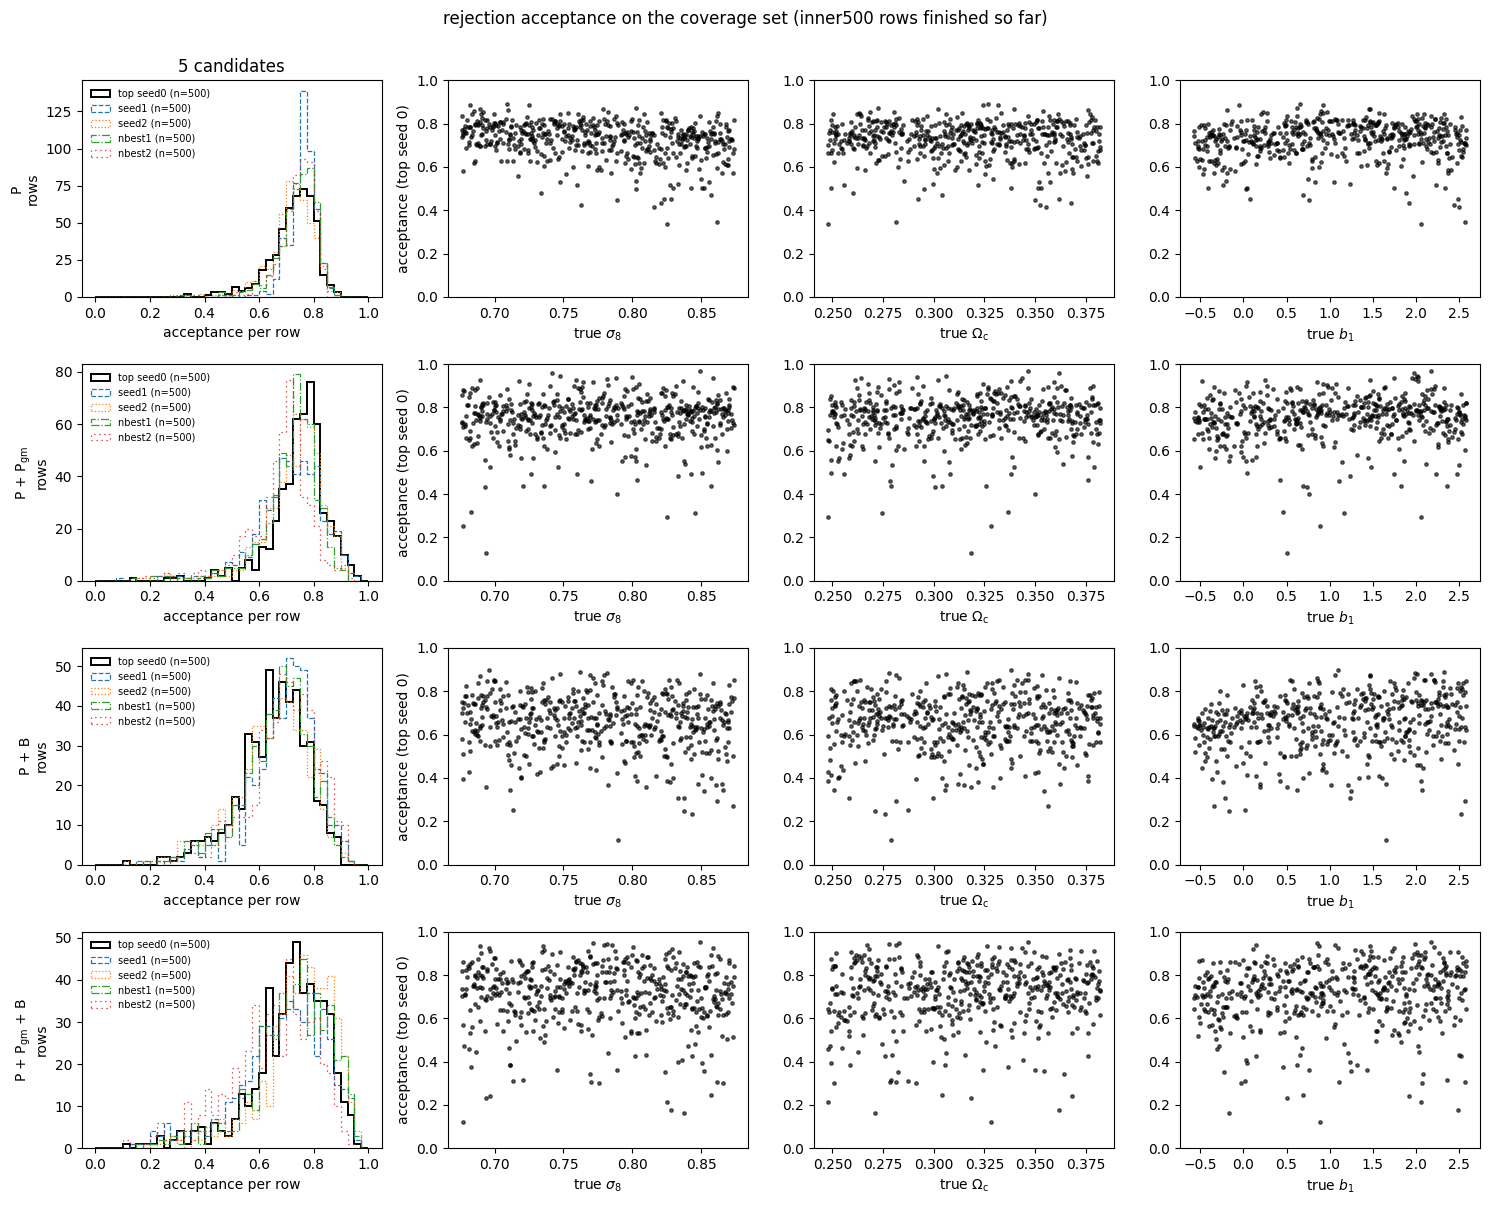

In [13]:
# C, part 2: Coverage rows: where is acceptance low? (rejection acceptance per row)
_lk_bia = pd.read_csv(REPO_ROOT / "data" / "params" / "params_lh_biasnoisecoveragev2_p9_n1000.txt", index_col=0)
lk_truth = {"sigma8_cold": lk_truth_s8, "omega_cold": _lk_cos.loc[lk_idxs, "omega_cold"].to_numpy(),
            "b1": _lk_bia.loc[lk_idxs, "b1"].to_numpy()}
LK_X = [("sigma8_cold", r"true $\sigma_8$"), ("omega_cold", r"true $\Omega_{\rm c}$"), ("b1", r"true $b_1$")]
fig, axes = plt.subplots(len(LK_COMBOS), 1 + len(LK_X), figsize=(15, 3.0 * len(LK_COMBOS)), squeeze=False)
for r_, lab in enumerate(LK_COMBOS):
    ax0 = axes[r_, 0]
    bins = np.linspace(0, 1, 41)
    for m, ls in zip(LK_MEMBERS, ["-", "--", ":", "-.", (0, (1, 3))]):
        rm = lk_res[(lab, m, "coverage")]
        if rm is not None and rm["acc"] is not None:
            ax0.hist(rm["acc"], bins=bins, histtype="step", ls=ls, lw=1.4 if m == "" else 0.9,
                     color="k" if m == "" else None, label=f"{m.strip('_') or 'top seed0'} (n={len(rm['acc'])})")
    ax0.set_xlabel("acceptance per row"); ax0.set_ylabel(f"{lab}\nrows"); ax0.legend(fontsize=7, frameon=False)
    res = lk_res[(lab, "", "coverage")]
    for c, (p, xl) in enumerate(LK_X, start=1):
        ax = axes[r_, c]
        if res is not None and res["acc"] is not None:
            ax.scatter(lk_truth[p][res["keep"]], res["acc"], s=6, alpha=0.6, color="k")
        ax.set_xlabel(xl); ax.set_ylim(0, 1)
        if c == 1:
            ax.set_ylabel("acceptance (top seed 0)")
axes[0, 0].set_title("5 candidates")
fig.suptitle(f"rejection acceptance on the coverage set ({LK_SUB} rows finished so far)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "prior_acceptance_coverage_rand16.pdf", bbox_inches="tight")
plt.show()


**Findings (2026-11-20, partial coverage).** The v1 leakage is gone: in every model and test the fraction of samples outside the physical box is ≤ 4×10⁻⁷, all within ~10⁻⁷ of the box width (float32 round-off at the edges), vs 17–37% in v1. Rejection acceptance on the coverage rows has a median of 0.66–0.77, with a tail to ~0.1; the tail is widest for P + B and P + P$_{\rm gm}$ + B (8–18% of rows below 0.5). Low-acceptance rows don't line up with the true σ8, Ω_c or b1 edges, so it's not one corner of the prior. On SHAMe and the phase-matched mocks acceptance is 0.81–0.98. Nothing here separates the ensemble candidates. Acceptance only costs sampling time; the truncated posterior is the correct one.

## D. Paper Fig 7: SHAMe vs phase-matched mock across n̄

Needs the shared setup only.

### D1. Paper Fig 7 with the top model only: SHAMe vs phase-matched mock across n̄

Paper Fig 7 (`plotter_figs.plot_fig7_noise_impact_contours_nbars`) for the top setting, seed 0 alone (`k_members=1`), P + P$_{\rm gm}$ + B at the fiducial cuts. Filled: SHAMe at the 3 densities. Unfilled, orange shades matched by n̄: the phase-matched mock (SHAMe ICs + our forward model, mean of 10 noise realizations) at the same densities. The two share the truth at each n̄, so the offset between same-shade filled and unfilled contours is the model-mismatch part of the SHAMe bias. The paper version uses the ensemble (needs the other members' matched tests).

SAVE_FIGURES: True
FIG_DIR: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks
FIG_DIR_LATEST: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks
OVERWRITE_FIGURES: True
FIG_EXT: pdf
Found 6/6 (K=1 ensemble).


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks/fig7_shame_vs_matched_nbars_topmodel.pdf


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-19_v2_checks/fig7_shame_vs_matched_nbars_topmodel.pdf


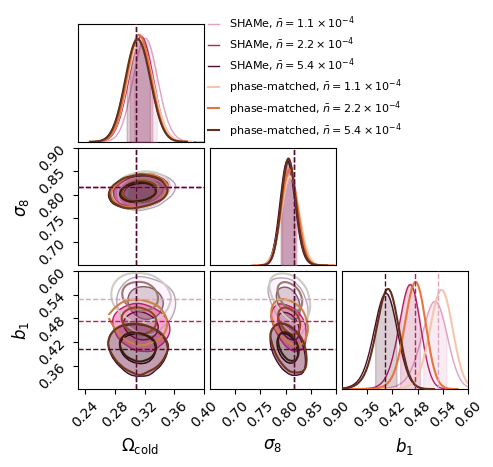

In [14]:
# D1: Fig 7, top model only
import plotter_figs as pf
pf.configure_figures(save=True, fig_dir=FIG_DIR, fig_dir_latest=FIG_DIR, ext="pdf")
pf.plot_fig7_noise_impact_contours_nbars(save_name="fig7_shame_vs_matched_nbars_topmodel", k_members=1)


#### D1b. With $b_2$ and $b_{s^2}$, every statistic combination

Top model only, (Ω_c, σ8, b1, b2, b_{s²}) via `param_names=`, one figure per combination at its fiducial cuts (`statistics=`). Filled: SHAMe at the 3 densities, shaded in the combination's paper color. Unfilled orange: the phase-matched mock. Ω_c and σ8 span the full prior; b1 keeps the paper zoom [0.3, 0.6] for the P$_{\rm gm}$ combos and widens to [0, 1.1] for P and P + B; b2 and b_{s²} use the samples' range. Truth lines are the SHAMe-fitted bias values at each n̄.

In [ ]:
# D1b: Fig 7, top model only, with b2 and b_s², for every statistic combo at its fiducial cuts
import plotter_figs as pf
import ensemble_kmax_utils as eku
pf.configure_figures(save=True, fig_dir=FIG_DIR, fig_dir_latest=FIG_DIR, ext="pdf")
for stats, _ in eku.iter_fiducial_configs():
    pf.plot_fig7_noise_impact_contours_nbars(
        save_name=f"fig7_shame_vs_matched_nbars_topmodel_b2bs2_{'_'.join(stats)}", k_members=1,
        param_names=["omega_cold", "sigma8_cold", "b1", "b2", "bs2"], statistics=stats,
        extents=None if "pgm" in stats else {"b1": [0.0, 1.1]})   # without P_gm, b1 is ~3x broader

## E. CV mean: $\Omega_m$, $\sigma_8$ and $S_8$

Needs the shared setup only. Posteriors on the mean data vector of the 1000-mock SHAMe-cosmology CV set (`_cvshamev2_p0_n1000 ... _mean`), top-3 ensemble, fiducial cuts, all 4 statistic combinations.

$S_8 \equiv \sigma_8\,(\Omega_m/0.3)^{0.5}$, computed per draw. $m_\nu = 0$ in training and test, so $\Omega_m = \Omega_{\rm cold}$ and $\sigma_8 = \sigma_{8,\rm cold}$ exactly.

The P$_{\rm gm}$ combos (kpgm0.37) use only member 0 until members 1–2 are tested on the CV mean; the cell prints which points are partial.

In [ ]:
# E: CV-mean posteriors in (Ω_m, σ8, S8), with S8 = σ8 (Ω_m / 0.3)^0.5.
# m_ν = 0 in training and test, so Ω_m = Ω_cold and σ8 = σ8_cold exactly; S8 is computed per posterior draw.
import plotter
import plotter_figs as pf
import ensemble_kmax_utils as eku

eku.set_ensemble_scheme("top3_settings")
_allow_prev = eku.ALLOW_PARTIAL_ENSEMBLES
eku.set_allow_partial_ensembles(True)   # P_gm combos at kpgm0.37: members 1-2 not tested on the CV mean yet
pf.configure_figures(save=True, fig_dir=FIG_DIR, fig_dir_latest=FIG_DIR, ext="pdf")

def s8_of(om, s8):
    return s8 * np.sqrt(om / 0.3)

E_NAMES = ["omega_cold", "sigma8_cold", "S8"]
_cv_truth = pd.read_csv(REPO_ROOT / "data" / "params" / "params_fixed_cvshamev2_p0_n1000.txt").iloc[0]
assert _cv_truth["neutrino_mass"] == 0.0
E_TRUTH = np.array([_cv_truth["omega_cold"], _cv_truth["sigma8_cold"],
                    s8_of(_cv_truth["omega_cold"], _cv_truth["sigma8_cold"])])

e_samples, e_labels, e_colors, e_rows = [], [], [], []
for (stats, mask), color in zip(eku.iter_fiducial_configs(), pf.COLORS_FID):
    s, pn, err = pf._ensemble_samples_for(stats, mask, test_mode="cvmean")
    lab = pf.get_stat_label_short(stats)
    if s is None:
        print(f"skip {lab}: {err}")
        continue
    s = s[:, 0, :] if s.ndim == 3 else s
    om, sig8 = s[:, pn.index("omega_cold")], s[:, pn.index("sigma8_cold")]
    x = np.column_stack([om, sig8, s8_of(om, sig8)])
    x = x[np.isfinite(x).all(axis=1)]
    e_samples.append((x, E_NAMES)); e_labels.append(lab); e_colors.append(color)
    mu, sd = x.mean(axis=0), x.std(axis=0)
    row = {"combo": lab}
    for j, name in enumerate(["Ω_m", "σ8", "S8"]):
        row[f"{name} mean"] = mu[j]
        row[f"σ({name})"] = sd[j]
        row[f"{name} (mean−truth)/σ"] = (mu[j] - E_TRUTH[j]) / sd[j]
    row["corr(Ω_m, σ8)"] = np.corrcoef(x[:, 0], x[:, 1])[0, 1]
    e_rows.append(row)
eku.report_partial_ensembles("E: CV mean, Ω_m / σ8 / S8")
eku.set_allow_partial_ensembles(_allow_prev)

print(f"truth: Ω_m = {E_TRUTH[0]:.4f}, σ8 = {E_TRUTH[1]:.4f}, S8 = {E_TRUTH[2]:.4f}")
display(pd.DataFrame(e_rows).set_index("combo").round(4))

fig = plotter.plot_contours_inf(
    param_names=E_NAMES, idx_obs=0, theta_obs_true=E_TRUTH,
    inf_methods=["sbi"] * len(e_samples), tags_inf=e_labels, tags_test=[""] * len(e_samples),
    colors=e_colors, labels=e_labels, samples_list=e_samples,
    figsize=pf.FIGSIZE_CORNER, fontsize_legend=9, unreparameterize=False, show=False)
pf.save_figure(fig, "cvmean_om_s8_S8_fiducial")
plt.show()